<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/30_QML_Defences_Against_ML_Attacks/QGAN_AdversarialPurification_Stanly2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QGAN for adversarial purification: HQMSGAN (Stanly et al., 2026) step by step

This notebook re-implements, runs and checks the method of

> Hamil Stanly, Mercy Shalinie Selvaraj and Riji Paul,
> "HQMSGAN: Enhancing Adversarial Robustness Using Hybrid Quantum-Classical Multi-Scale Generative Adversarial Network",
> *Entropy* 28(10), 1089 (2026). https://doi.org/10.3390/e28101089

The paper publishes no code ("data available on request"), so everything below is written from the method as the paper describes it,
with the stack it names: PennyLane (Xanadu) + PyTorch. The paper simulated its circuits on Amazon Braket SV1; here a local noiseless
state-vector simulation is used.

**What the notebook does.** It builds a *defence against adversarial examples*. An image classifier (the "victim") is attacked with the
four white-box attacks of the paper (FGSM, BIM, MIM, PGD). A **hybrid quantum-classical generator** (convolutional encoder -> small
variational quantum circuit -> decoder) is then trained, together with **three classical critics that look at the image at three
scales**, as a Wasserstein GAN with gradient penalty. Its task is to turn an attacked image back into the clean image ("purification")
so that the *unchanged* victim classifies it correctly again. The notebook reproduces the paper's pipeline end to end on MNIST and
Fashion-MNIST, measures the accuracy of the victim before and after purification, the image quality (SSIM, PSNR, a Frechet distance), the
ablations of the paper (classical instead of quantum generator, number of critics, size of the circuit, leave-one-loss-out), compares
against classical baselines, and finally puts every number the paper reports next to ours with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime (no GPU, no quantum account needed) and use *Runtime -> Run all*. The
first cell installs PennyLane; if Colab asks to restart the session, restart and run all again.

**Scale.** The paper trains on all 60 000 images for 50 epochs per circuit (47 000 optimiser steps, nine circuits, two datasets, several
epsilons) on cloud simulators. That is not possible in a class session, so this notebook uses a **4-class subset of each dataset, images
down-scaled to 14x14, a few hundred training images and 12-30 epochs** (a few hundred optimiser steps). Every such reduction is listed in
the table "What follows the paper and what had to be chosen" and marked `# CHOICE:` in the code. Absolute accuracies are therefore *not*
comparable with the paper's tables; what can be tested is the paper's qualitative claims and the size of its effects.

**Runtime.** `FAST_MODE = True`: about 8-10 minutes on a laptop CPU (one seed, one epsilon, two ablations). `FAST_MODE = False`: the larger
run (three seeds, eps 0.3 and 0.5, three circuits, all ablations), about 90 minutes on a 2-4 core CPU.

**What you get at the end.** Tables of attacked-vs-purified accuracy, purified images and confusion matrices, the ablations, five classical
baselines, an adaptive-attack test that the paper did not do, and the claim-by-claim comparison with the paper.

## The paper in one page

**Problem.** Image classifiers can be fooled by small, deliberately computed perturbations ("adversarial examples"). The paper asks whether a
*hybrid quantum-classical generative network* can remove such perturbations ("purify" the image) better than its classical counterpart.

**Threat model.** White-box gradient attacks on the classifier: FGSM (one step, `x + eps * sign(grad)`), BIM (iterated FGSM, step 0.03, 10 steps),
MIM (BIM with momentum 1.0 and L1-normalised gradients) and PGD (BIM with a random start), all with an L-infinity budget `eps` in
{0.01, 0.05, 0.1, 0.2, 0.3, 0.5}. The attacker sees the classifier, **not** the purifier (Algorithm 1 attacks the classifier only).

**Defence (HQMSGAN, Algorithm 2).**
1. *Generator* = encoder + VQC + decoder. Three strided 3x3 convolutions (1 -> 32 -> 64 -> 128 channels, strides 1, 2, 2) compress the 28x28 image;
   the code is mapped to `q` numbers, one per qubit (q in {4, 6, 8}). The **variational quantum circuit** angle-embeds them with `RY`, applies a
   trainable `RY, RZ` on each qubit, then `l` layers (l in {4, 6, 8}) of trainable `RX, RY` followed by a CNOT chain q0 -> q1 -> ... , and reads out
   `<Z>` on every qubit. This gives `2q + 2ql` trainable parameters (Table 6: 40 for q4l4 ... 144 for q8l8). A projection layer and transposed
   convolutions decode the `q` expectation values back to an image. Gradients through the circuit use the parameter-shift rule.
2. *Three classical critics* with inputs of 28x28, 14x14 and 7x7 pixels (conv, LeakyReLU, InstanceNorm, linear -> Wasserstein score), trained with a
   gradient penalty (WGAN-GP). Critic loss = sum of the three (Eqs. 20-25).
3. *Generator loss* (Eq. 19) = 0.001 adversarial + 15 reconstruction (0.5 MSE + 0.5 L1) + 8 classification (cross entropy of the *victim* on the purified
   image) + 15 feature (MSE between victim features of purified and clean image) + 10 saliency (distance between gradient-saliency maps of purified and
   clean image).
4. *Adversarial training*: the generator is fed the union of clean and attacked images and must output the clean image. At test time the attacked image
   goes through the generator and the unchanged victim classifies the result.

**Data and training.** MNIST and Fashion-MNIST (60 000 / 10 000, 28x28, ten classes). Adam (lr 1e-4 generator, 5e-5 critics, betas 0.5 / 0.999), batch 32 or 64,
50 epochs, nine circuits (q x l = {4,6,8} x {4,6,8}), eps in {0.3, 0.5} for the main tables, victim = CNN of Table 2.

**Claims to check.**
- Table 7 / 8: for every circuit, attack and eps the purified accuracy is higher than the attacked accuracy (MNIST q4l4, eps 0.3: FGSM 82.6 -> 84.7, BIM 81.0 -> 84.8,
  MIM 75.1 -> 79.9, PGD 67.5 -> 70.9; Fashion q4l4, eps 0.3: 49.5 -> 53.5, 46.4 -> 50.5, 40.6 -> 44.6, 39.4 -> 41.3). Clean accuracy 98.04 % (MNIST) and 81.23 % (Fashion).
- SSIM, PSNR, FID and LPIPS of the purified images are better than those of the attacked images (Figs. 11-16).
- Bigger circuits (more qubits / layers) give better results (Sec. 6.4.1); the quantum generator beats a classical one (Table 12); three critics beat two beat one
  (Tables 13-14); every loss term matters (Table 15).
- HQMSGAN beats Shi et al.'s QCNN defence, MagNet, DefenseGAN and the Collaborative Defence GAN (Tables 9-11).

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Datasets | MNIST, Fashion-MNIST, 10 classes, 28x28, 60 000 / 10 000 images | classes 0-3 only (MNIST: digits 0-3; Fashion: T-shirt, trouser, pullover, dress), 2x2 average-pooled to **14x14**; `CLF` 300-600 / `GAN` 100-250 / test 100-250 images per class |
| Victim classifier | Table 2 CNN: Conv32-Pool-Conv64-Pool-FC128-FC10 | same layout with 16 / 32 filters, 4 outputs, trained 8-15 epochs (Adam) on its own images |
| Attacks | FGSM, BIM, MIM, PGD; eps 0.01 ... 0.5; alpha 0.03, 10 steps, mu 1.0 | same four attacks written from Eqs. 7-13; alpha 0.03, 10 steps, mu 1.0 (so BIM/MIM cannot exceed 0.3 even for eps 0.5, as in the paper); PGD uses a random start and a fixed 10 steps (Algorithm 1 says 10/20/30, Table 5 says 10) |
| Who is attacked | the classifier only | the same (non-adaptive); an adaptive attack through the purifier is added as an extra |
| Generator | 3 convs (32/64/128), flatten -> q features, VQC, projection, transposed convs | 3 convs (8/16/32, strides 1/2/2), one linear layer + `pi*tanh` to q angles (the paper does not say how 128x7x7 maps to q), VQC, linear projection, ConvTranspose + Conv + sigmoid |
| VQC | angle embedding RY; RY, RZ; l x (RX, RY, CNOT chain); `<Z>` on every qubit; 2q + 2ql parameters | exactly this, as a PennyLane QNode; parameter counts reproduce Table 6; small random initial weights (N(0, 0.1), not given) |
| Circuits | nine: q, l in {4,6,8} | q4l4 for everything; `FAST_MODE=False` adds q6l4 and q8l4 (circuit-size ablation) |
| Gradient rule | parameter-shift on AWS Braket SV1 | exact back-propagation through a noiseless state-vector simulation; the notebook checks it equals the parameter-shift gradient to 1e-14; no shots, no noise, no hardware |
| Critics | three, 28x28 / 14x14 / 7x7, conv + LeakyReLU + InstanceNorm + linear | three, 14x14 / 7x7 / 4x4, same blocks (smaller widths) |
| WGAN-GP details | lambda_1..3 symbolic; critic steps not given | lambda = 10, one critic step per generator step, adversarial loss averaged over the three critics |
| Classical-generator ablation | "a neural network with linear and ReLU layers" | Linear(q,q)-LeakyReLU-Linear(q,q) (40 parameters for q = 4); a plain ReLU collapsed to a constant output in our first trials |
| Generator loss | Eq. 19 weights 0.001 / 15 / 8 / 15 / 10 | the same weights; features = 128-d penultimate layer of the victim; saliency = `abs(d logit_y / d x)` compared with MSE |
| Training pairs | "clean U adversarial" (not specified further) | each step every image is replaced, with probability 1/5 each, by itself or by its FGSM / BIM / MIM / PGD version at the training eps; the purifier's training images are disjoint from the victim's and from the test images; one purifier per (dataset, eps) |
| Optimiser | Adam, lr 1e-4 / 5e-5, betas 0.5 / 0.999, 50 epochs on 60 000 images | Adam, lr 1e-3 / 5e-4 (10x, because we take about 50-100x fewer steps), betas 0.5 / 0.999, batch 32, 12-30 epochs on 400-600 images; no early stopping, no choice made on the test images |
| Metrics | accuracy, SSIM, PSNR (MAX = 255), FID (Inception), LPIPS | accuracy, SSIM (7x7 Gaussian window), PSNR (MAX = 1), a Frechet distance on the victim's 128-d features (Inception does not fit 14x14 images), LPIPS not computed |
| Repeats | none reported | seeds 42, 43, 44 for the main run (mean +- std) when `FAST_MODE=False` |
| Compared defences | Shi et al. QCNN, MagNet, DefenseGAN, Collaborative Defence GAN (numbers copied from their papers, different classifiers) | not reproducible from the text; instead: no defence, median filter, PGD adversarial training of the classifier, Random Forest and SVC (RBF) on pixels |

## 0. Setup

The next cells install PennyLane (Colab already ships PyTorch, scikit-learn and matplotlib), collect **every tunable constant in one configuration cell**
(`FAST_MODE`, sizes, budgets, seeds), and import the libraries with their versions printed. Everything random is seeded: Python, NumPy and PyTorch through
`set_seed`, the per-epoch shuffles, the PGD random start and the weight initialisation of every model (PennyLane's simulator is analytic, so there is no
shot noise).

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" pyarrow huggingface_hub
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")

PennyLane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE   = False        # True: class demo (a few minutes). False: the larger run (see the runtime note in the header).
SEED        = 42          # CHOICE: the paper gives no seed
N_THREADS   = 2           # CHOICE: CPU threads for PyTorch (the models are tiny)

# --- data (the paper: full MNIST / Fashion-MNIST, 10 classes, 28x28; here a small subset) ---
CLASSES     = [0, 1, 2, 3]   # CHOICE: first four classes of each dataset (MNIST 0-3; Fashion: T-shirt, trouser, pullover, dress)
IMG         = 14             # CHOICE: images are 2x2 average-pooled from 28x28 to 14x14 (paper: 28x28)
N_CLF_PER_CLASS  = 300 if FAST_MODE else 600     # classifier (victim) training images per class
N_GAN_PER_CLASS  = 100 if FAST_MODE else 150     # purifier (GAN) training images per class
N_TEST_PER_CLASS = 100 if FAST_MODE else 250     # test images per class (never used for any fitting or choice)
DATASETS    = ["mnist", "fashion"]

# --- attacks (paper Table 5: eps in {0.01,...,0.5}; BIM/MIM/PGD alpha = 0.03, 10 steps, MIM mu = 1.0) ---
ATTACKS     = ["FGSM", "BIM", "MIM", "PGD"]
EPS_TRAIN   = [0.3] if FAST_MODE else [0.3, 0.5]            # eps at which a purifier is trained and tested
EPS_CURVE   = [0.1, 0.3] if FAST_MODE else [0.01, 0.05, 0.1, 0.2, 0.3, 0.5]   # attack-only accuracy curve
ALPHA, STEPS, MU = 0.03, 10, 1.0

# --- hybrid quantum-classical generator (paper: q in {4,6,8} qubits x l in {4,6,8} layers) ---
QUANTUM_BACKEND  = "torch"      # "torch": exact state-vector simulation written in torch (fast, verified against PennyLane below);
                                # "pennylane": the PennyLane QNode (the paper's framework), about 5x slower inside the training loops
QUBIT_LAYER_MAIN = (4, 4)                                    # the (q, l) circuit used for the main experiments
QUBIT_LAYER_GRID = [(4, 4)] if FAST_MODE else [(4, 4), (6, 4), (8, 4)]   # CHOICE: sub-grid of the paper's nine circuits
# --- GAN training (paper: Adam, 50 epochs, batch 64, lr_g 1e-4, lr_d 5e-5, beta 0.5/0.999) ---
EPOCHS      = 12 if FAST_MODE else 30       # CHOICE: far fewer steps than the paper's 50 epochs on 60 000 images
BATCH       = 32
LR_G, LR_D  = 1e-3, 5e-4                    # CHOICE: 10x the paper's rates because we take ~50x fewer optimiser steps
BETAS       = (0.5, 0.999)
GP_LAMBDA   = 10.0                          # CHOICE: the paper gives lambda_1..3 only symbolically; 10 is the WGAN-GP default
LOSS_W      = dict(adv=0.001, rec=15.0, cls=8.0, fea=15.0, sal=10.0)   # paper Eq. (19)
N_SEEDS     = 1 if FAST_MODE else 3         # repeats of the main experiment (mean +- std)
RUN_ABLATIONS = True                        # classical generator, 1/2/3 discriminators, loss ablation (main circuit, eps = 0.3)

# --- victim classifier (paper Table 2 scaled to 14x14) ---
CLF_EPOCHS  = 8 if FAST_MODE else 15

DATA_DIR    = "data"        # where the datasets are cached (relative to the working directory)
IBM_TOKEN   = ""            # unused: the paper simulates on AWS Braket SV1; here PennyLane's local statevector simulator

In [3]:
import os, io, time, copy, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

torch.set_num_threads(N_THREADS)
os.makedirs(DATA_DIR, exist_ok=True)

def set_seed(s):
    """Fix every random number generator the notebook uses (python, numpy, torch)."""
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

set_seed(SEED)
print("torch", torch.__version__, "| pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
import sklearn; print("scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| seeds:", N_SEEDS, "| epochs:", EPOCHS, "| eps trained:", EPS_TRAIN)

torch 2.14.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6
scikit-learn 1.9.1
FAST_MODE = False | seeds: 3 | epochs: 30 | eps trained: [0.3, 0.5]


## 1. Data: MNIST and Fashion-MNIST, reduced

Both datasets are downloaded inside the notebook from public Hugging Face mirrors (`ylecun/mnist`, `zalando-datasets/fashion_mnist`; fallback: OpenML) and cached in
`DATA_DIR`. To make a quantum-GAN experiment feasible on a CPU we keep **four classes** (the first four labels), **down-scale the images to 14x14** by average pooling
and draw three *disjoint*, class-balanced subsets:

* `clf`: images to train the **victim classifier** (the model that is attacked),
* `gan`: images to train the **purifier** (the HQMSGAN generator and its critics),
* `test`: held-out images from the official test split, used only for the final numbers. Nothing is fitted or chosen on them.

Pixels are scaled to [0, 1], which is the range the attacks clip to.

In [4]:
from PIL import Image

HF_FILES = {   # public Hugging Face dataset mirrors (parquet with PNG bytes)
    "mnist":   ("ylecun/mnist",                   "mnist/{split}-00000-of-00001.parquet"),
    "fashion": ("zalando-datasets/fashion_mnist", "fashion_mnist/{split}-00000-of-00001.parquet"),
}
OPENML = {"mnist": "mnist_784", "fashion": "Fashion-MNIST"}   # fallback: OpenML through scikit-learn

def _decode(df):
    imgcol = [c for c in df.columns if "image" in c.lower() or c == "img"][0]
    X = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df[imgcol]]).astype(np.uint8)
    return X, df["label"].to_numpy().astype(int)

def load_raw(name):
    """Return (Xtr, ytr, Xte, yte) of the full 28x28 uint8 dataset, cached in DATA_DIR."""
    cache = os.path.join(DATA_DIR, f"{name}_28.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["Xtr"], z["ytr"], z["Xte"], z["yte"]
    try:
        from huggingface_hub import hf_hub_download
        repo, pattern = HF_FILES[name]
        parts = []
        for split in ("train", "test"):
            p = hf_hub_download(repo, pattern.format(split=split), repo_type="dataset", cache_dir=DATA_DIR)
            parts.append(_decode(pd.read_parquet(p)))
        (Xtr, ytr), (Xte, yte) = parts
        print(f"{name}: downloaded from Hugging Face ({repo})")
    except Exception as e:                       # fallback: OpenML (70 000 images, first 60 000 = train)
        from sklearn.datasets import fetch_openml
        print(f"{name}: Hugging Face failed ({type(e).__name__}); using OpenML")
        d = fetch_openml(OPENML[name], version=1, as_frame=False, data_home=DATA_DIR, parser="liac-arff")
        X = d.data.reshape(-1, 28, 28).astype(np.uint8); y = d.target.astype(int)
        Xtr, ytr, Xte, yte = X[:60000], y[:60000], X[60000:], y[60000:]
    np.savez_compressed(cache, Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte)
    return Xtr, ytr, Xte, yte

def downscale(X28):
    """uint8 (N,28,28) -> float32 (N,1,IMG,IMG) in [0,1] by average pooling."""
    t = torch.from_numpy(X28.astype(np.float32) / 255.0)[:, None]
    return F.adaptive_avg_pool2d(t, IMG)

def make_splits(name, rng):
    """Class-balanced, disjoint classifier-train / GAN-train / test subsets (test comes from the official test split)."""
    Xtr, ytr, Xte, yte = load_raw(name)
    out = {k: ([], []) for k in ("clf", "gan", "test")}
    for new_label, c in enumerate(CLASSES):
        itr = rng.permutation(np.where(ytr == c)[0]); ite = rng.permutation(np.where(yte == c)[0])
        a, b = N_CLF_PER_CLASS, N_CLF_PER_CLASS + N_GAN_PER_CLASS
        for key, idx, X in (("clf", itr[:a], Xtr), ("gan", itr[a:b], Xtr), ("test", ite[:N_TEST_PER_CLASS], Xte)):
            out[key][0].append(downscale(X[idx])); out[key][1].append(torch.full((len(idx),), new_label))
    res = {}
    for key, (xs, ys) in out.items():
        x, y = torch.cat(xs), torch.cat(ys)
        p = torch.from_numpy(rng.permutation(len(y)))
        res[key] = (x[p], y[p])
    return res

SPLITS = {}
t0 = time.time()
for name in DATASETS:
    SPLITS[name] = make_splits(name, np.random.default_rng(SEED))
    sz = {k: tuple(v[0].shape) for k, v in SPLITS[name].items()}
    print(f"{name:8s} {sz}   class counts (test): {torch.bincount(SPLITS[name]['test'][1]).tolist()}")
print(f"data ready in {time.time()-t0:.1f} s")

mnist    {'clf': (2400, 1, 14, 14), 'gan': (600, 1, 14, 14), 'test': (1000, 1, 14, 14)}   class counts (test): [250, 250, 250, 250]


fashion  {'clf': (2400, 1, 14, 14), 'gan': (600, 1, 14, 14), 'test': (1000, 1, 14, 14)}   class counts (test): [250, 250, 250, 250]
data ready in 1.1 s


A first look at the reduced data (one row per class).

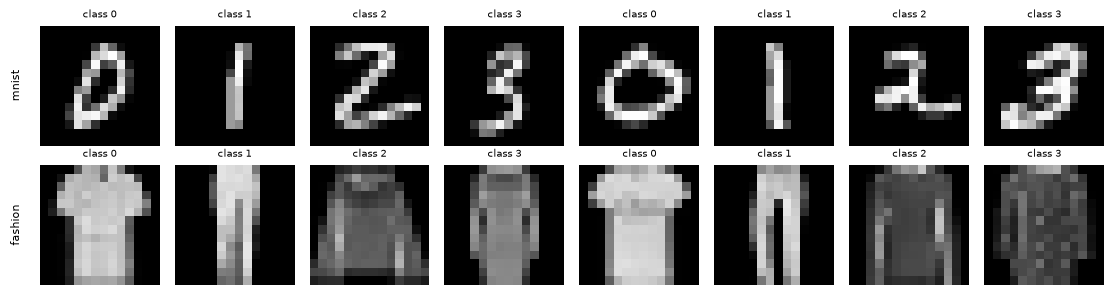

In [5]:
fig, axs = plt.subplots(len(DATASETS), 8,figsize=(1.4 * 8, 1.5 * len(DATASETS)))
for r, name in enumerate(DATASETS):
    x, y = SPLITS[name]["test"]
    for c in range(8):
        i = int(torch.where(y == c % len(CLASSES))[0][c // len(CLASSES)])
        axs[r, c].imshow(x[i, 0], cmap="gray", vmin=0, vmax=1); axs[r, c].axis("off"); axs[r, c].set_title(f"class {CLASSES[c % len(CLASSES)]}", fontsize=7)
    axs[r, 0].text(-0.15, 0.5, name, transform=axs[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
plt.tight_layout(); plt.show()

## 2. The victim classifier and the four white-box attacks

**Victim.** A small CNN with the layout of the paper's Table 2 (Conv-ReLU-MaxPool, Conv-ReLU-MaxPool, FC-ReLU, FC). The purifier will *not* modify it; it is trained once and
frozen. Its accuracy on clean test images is the ceiling for any defence.

**Attacks (Algorithm 1, Eqs. 7-13).** All four use the gradient of the cross-entropy loss with respect to the *input pixels* and keep the perturbation inside the L-infinity
ball of radius `eps`:

* **FGSM**: one step, `x + eps * sign(grad)`.
* **BIM**: ten steps of size 0.03, each followed by clipping to `[x-eps, x+eps]` and `[0, 1]`.
* **MIM**: like BIM, but the gradient is divided by its L1 norm and accumulated with momentum `mu = 1.0` (Eq. 11).
* **PGD**: like BIM but starting from a random point in the eps-ball.

Note that with `alpha = 0.03` and 10 steps BIM/MIM can move a pixel by at most 0.3, so for `eps = 0.5` they are not stronger than for `eps = 0.3`; this is how the paper
specifies them (Table 5) and we keep it.

In [6]:
N_CLASSES = len(CLASSES)

class Classifier(nn.Module):
    """Paper Table 2 scaled to 14x14: Conv-ReLU-Pool, Conv-ReLU-Pool, FC-ReLU, FC.
    CHOICE: 16/32 filters instead of 32/64, 128 hidden units as in the paper."""
    def __init__(self, n_out=N_CLASSES):
        super().__init__()
        self.c1 = nn.Conv2d(1, 16, 3, padding=1); self.c2 = nn.Conv2d(16, 32, 3, padding=1)
        self.fc1 = nn.Linear(32 * (IMG // 4) ** 2, 128); self.fc2 = nn.Linear(128, n_out)
    def features(self, x):                     # penultimate (128-d) representation, used by the feature loss and for the FD score
        x = F.max_pool2d(F.relu(self.c1(x)), 2)
        x = F.max_pool2d(F.relu(self.c2(x)), 2)
        return F.relu(self.fc1(x.flatten(1)))
    def forward(self, x):
        return self.fc2(self.features(x))

def train_classifier(x, y, epochs, seed, lr=2e-3, bs=64, attack_fn=None):
    """Adam + cross entropy. With attack_fn the model is adversarially trained (classical baseline)."""
    set_seed(seed)
    m = Classifier(); opt = torch.optim.Adam(m.parameters(), lr=lr)
    for ep in range(epochs):
        m.train(); p = torch.randperm(len(y))
        for i in range(0, len(y), bs):
            b = p[i:i + bs]; xb, yb = x[b], y[b]
            if attack_fn is not None:
                m.eval(); xb = attack_fn(m, xb, yb); m.train()
            loss = F.cross_entropy(m(xb), yb); opt.zero_grad(); loss.backward(); opt.step()
    for q in m.parameters(): q.requires_grad_(False)
    return m.eval()

@torch.no_grad()
def accuracy(model, x, y, bs=500):
    return float(torch.cat([(model(x[i:i + bs]).argmax(1) == y[i:i + bs]).float() for i in range(0, len(y), bs)]).mean())

# ---------------- the four white-box attacks of the paper (Algorithm 1), pixels clipped to [0, 1] ----------------
def _grad(model, x, y):
    x = x.clone().requires_grad_(True)
    loss = F.cross_entropy(model(x), y)
    return torch.autograd.grad(loss, x)[0]

def fgsm(model, x, y, eps):
    return (x + eps * _grad(model, x, y).sign()).clamp(0, 1).detach()

def bim(model, x, y, eps, alpha=ALPHA, steps=STEPS):
    xa = x.clone()
    for _ in range(steps):
        xa = xa + alpha * _grad(model, xa, y).sign()
        xa = torch.min(torch.max(xa, x - eps), x + eps).clamp(0, 1).detach()
    return xa

def mim(model, x, y, eps, alpha=ALPHA, steps=STEPS, mu=MU):
    xa, g = x.clone(), torch.zeros_like(x)
    for _ in range(steps):
        gr = _grad(model, xa, y)
        g = mu * g + gr / gr.abs().flatten(1).sum(1).clamp_min(1e-12).view(-1, 1, 1, 1)   # L1-normalised gradient + momentum
        xa = xa + alpha * g.sign()
        xa = torch.min(torch.max(xa, x - eps), x + eps).clamp(0, 1).detach()
    return xa

def pgd(model, x, y, eps, alpha=ALPHA, steps=STEPS):
    xa = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)          # random start x0 = x + delta
    for _ in range(steps):
        xa = xa + alpha * _grad(model, xa, y).sign()
        xa = torch.min(torch.max(xa, x - eps), x + eps).clamp(0, 1).detach()
    return xa

ATTACK_FN = {"FGSM": fgsm, "BIM": bim, "MIM": mim, "PGD": pgd}

def craft_all(model, x, y, eps, bs=500):
    """Adversarial versions of x for all four attacks -> dict name -> tensor."""
    return {a: torch.cat([ATTACK_FN[a](model, x[i:i + bs], y[i:i + bs], eps) for i in range(0, len(y), bs)]) for a in ATTACKS}

# ---------------- train the victim classifiers (one per dataset) ----------------
CLF = {}
t0 = time.time()
for name in DATASETS:
    xc, yc = SPLITS[name]["clf"]; xt, yt = SPLITS[name]["test"]
    CLF[name] = train_classifier(xc, yc, CLF_EPOCHS, SEED)
    print(f"{name:8s} victim classifier: train acc {accuracy(CLF[name], xc, yc):.3f} | clean TEST acc {accuracy(CLF[name], xt, yt):.3f}"
          f"   (paper, 10 classes 28x28: MNIST ~98.0 %, Fashion ~81.2 %)")
print(f"{time.time()-t0:.1f} s")

mnist    victim classifier: train acc 0.996 | clean TEST acc 0.985   (paper, 10 classes 28x28: MNIST ~98.0 %, Fashion ~81.2 %)


fashion  victim classifier: train acc 0.952 | clean TEST acc 0.913   (paper, 10 classes 28x28: MNIST ~98.0 %, Fashion ~81.2 %)
25.9 s


### Attack strength without any defence

How much does each attack hurt the undefended victim as `eps` grows (the paper's grid, Table 5)? The paper does not show this curve; it is the reference for every defence below.

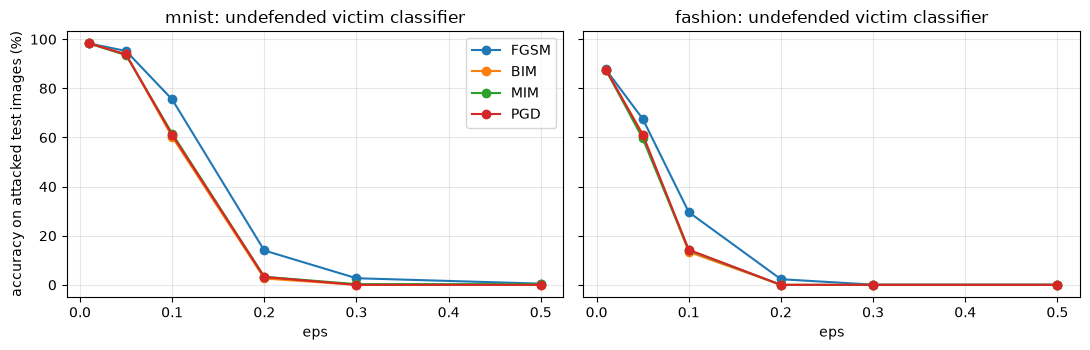

eps             0.01  0.05  0.10  0.20  0.30  0.50
dataset attack                                    
fashion BIM     87.6  61.2  13.4   0.0   0.0   0.0
        FGSM    87.7  67.6  29.6   2.3   0.1   0.1
        MIM     87.6  59.6  14.1   0.0   0.0   0.0
        PGD     87.6  61.2  14.3   0.0   0.0   0.0
mnist   BIM     98.3  93.8  60.3   2.6   0.0   0.0
        FGSM    98.3  95.2  75.5  14.0   2.7   0.5
        MIM     98.3  93.5  61.6   3.3   0.3   0.3
        PGD     98.3  93.8  61.1   3.2   0.0   0.0

Paper (Tables 7-8, ten classes, 28x28, q4l4 row): MNIST FGSM 82.6 %, PGD 67.5 % at eps 0.3 -- an undefended small CNN like ours
collapses to near 0 % at that eps, so the paper's 'attack' columns cannot come from an undefended white-box attack on this kind of classifier.


In [7]:
ADV = {}   # (dataset, eps) -> {"gan": {attack: tensor}, "test": {attack: tensor}}   (adversarial images crafted against the frozen victim classifier)
def adv_sets(name, eps):
    key = (name, round(eps, 4))
    if key not in ADV:
        set_seed(SEED + int(eps * 1000))                   # PGD uses a random start: fix it
        clf = CLF[name]
        ADV[key] = {k: craft_all(clf, SPLITS[name][k][0], SPLITS[name][k][1], eps) for k in ("gan", "test")}
    return ADV[key]

# attack strength without any defence: classifier accuracy vs eps (paper Table 5 grid)
rows = []
for name in DATASETS:
    xt, yt = SPLITS[name]["test"]
    for eps in EPS_CURVE:
        adv = adv_sets(name, eps)["test"]
        for a in ATTACKS:
            rows.append(dict(dataset=name, eps=eps, attack=a, acc=accuracy(CLF[name], adv[a], yt)))
curve = pd.DataFrame(rows)
fig, axs = plt.subplots(1, len(DATASETS), figsize=(11, 3.6), sharey=True)
for ax, name in zip(axs, DATASETS):
    for a in ATTACKS:
        d = curve[(curve.dataset == name) & (curve.attack == a)]
        ax.plot(d.eps, 100 * d.acc, "o-", label=a)
    ax.set_title(f"{name}: undefended victim classifier"); ax.set_xlabel("eps"); ax.grid(alpha=.3)
axs[0].set_ylabel("accuracy on attacked test images (%)"); axs[0].legend()
plt.tight_layout(); plt.show()
print(curve.pivot_table(index=["dataset", "attack"], columns="eps", values="acc").mul(100).round(1).to_string())
print("\nPaper (Tables 7-8, ten classes, 28x28, q4l4 row): MNIST FGSM 82.6 %, PGD 67.5 % at eps 0.3 -- an undefended small CNN like ours")
print("collapses to near 0 % at that eps, so the paper's 'attack' columns cannot come from an undefended white-box attack on this kind of classifier.")

## 3. The hybrid quantum-classical generator and the multi-scale critics

**The variational quantum circuit (Fig. 3, Sec. 5.4).** `q` qubits; the `q` numbers coming from the encoder are loaded as `RY` rotation angles (angle embedding); a trainable
`RY, RZ` pair on every qubit; then `l` layers, each a trainable `RX, RY` pair per qubit followed by a chain of CNOTs (q0->q1, q1->q2, ...) that entangles the qubits ("feature
coupling"); finally the Pauli-Z expectation value of each qubit is measured. These `q` numbers in [-1, 1] are the quantum features the decoder works from.
Trainable parameters: `2q + 2ql`; the first cell below reproduces the paper's Table 6 exactly. `make_vqc_qnode` is the PennyLane QNode (the paper's framework).

**A fast exact simulator.** PennyLane rebuilds the circuit description for every call, which dominates the run time of a GAN with thousands of steps on a 4-qubit circuit.
So the training loops use `torch_vqc`, a ~25-line batched state-vector simulator of the *same* circuit. The check cell shows that it agrees with PennyLane (back-propagation
and the parameter-shift rule that the paper uses on hardware-style devices) to machine precision, both in outputs and in gradients. Set `QUANTUM_BACKEND = "pennylane"` in
the configuration cell to train through the PennyLane QNode instead (about 5x slower).

**The generator** is encoder (three strided convolutions) -> linear map to `q` angles (`pi * tanh`) -> VQC -> linear projection -> decoder (transposed convolution + convolution +
sigmoid). In the **classical-generator ablation** (Sec. 6.4.3) the VQC is replaced by `Linear-ReLU-Linear` (the same number of parameters for q = 4).

**The critics.** Three classical critics (convolution, LeakyReLU, InstanceNorm, linear layer -> an unbounded Wasserstein score), one for the full image and one each for the
image average-pooled to half and to quarter size. They give the generator feedback about global structure and fine detail.

In [8]:
def make_vqc_qnode(n_qubits, n_layers, diff_method="backprop"):
    """The paper's VQC (Fig. 3 / Sec. 5.4): angle embedding (RY), trainable RY+RZ per qubit (2q parameters),
    then l layers of trainable RX+RY per qubit (2*q*l parameters) with a CNOT chain q0->q1->...->q(q-1);
    read-out: <Z> on every qubit. Total trainable parameters = 2q + 2*q*l (40 for q4l4, as in Table 6)."""
    dev = qml.device("default.qubit", wires=n_qubits)
    @qml.qnode(dev, interface="torch", diff_method=diff_method)
    def circuit(inputs, w_in, w_layers):
        qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation="Y")        # inputs: (batch, q), broadcast over the batch
        for q in range(n_qubits):
            qml.RY(w_in[q, 0], wires=q); qml.RZ(w_in[q, 1], wires=q)
        for l in range(n_layers):
            for q in range(n_qubits):
                qml.RX(w_layers[l, q, 0], wires=q); qml.RY(w_layers[l, q, 1], wires=q)
            for q in range(n_qubits - 1):
                qml.CNOT(wires=[q, q + 1])
        return [qml.expval(qml.PauliZ(q)) for q in range(n_qubits)]
    return circuit

_PERM_CACHE = {}
def _chain_perm(n):
    """Basis-state permutation of the CNOT chain CNOT(0,1), CNOT(1,2), ..., CNOT(n-2,n-1) (qubit 0 = most significant bit)."""
    if n not in _PERM_CACHE:
        def chain(k):
            b = [(k >> (n - 1 - j)) & 1 for j in range(n)]
            for q in range(n - 1):
                if b[q] == 1: b[q + 1] ^= 1
            return sum(v << (n - 1 - j) for j, v in enumerate(b))
        f = torch.tensor([chain(k) for k in range(2 ** n)])          # input basis state k -> output basis state f[k]
        inv = torch.empty_like(f); inv[f] = torch.arange(2 ** n)       # new_state[j] = old_state[inv[j]]
        zsign = torch.tensor([[1.0 - 2 * ((k >> (n - 1 - q)) & 1) for q in range(n)] for k in range(2 ** n)], dtype=torch.float64)
        _PERM_CACHE[n] = (inv, zsign)
    return _PERM_CACHE[n]

def torch_vqc(inputs, w_in, w_layers):
    """The same circuit as `make_vqc_qnode`, simulated directly with torch tensors (exact state vector, batched, autograd).
    PennyLane re-builds a circuit tape on every call, which dominates the run time of a GAN with thousands of calls; this
    ~25-line simulator gives identical numbers and gradients (checked below against PennyLane) several times faster."""
    B, n = inputs.shape
    cx = torch.complex128
    c, s = torch.cos(inputs / 2).to(cx), torch.sin(inputs / 2).to(cx)
    psi = torch.ones(B, *([1] * n), dtype=cx)
    for q in range(n):                                              # angle embedding: RY(x_q)|0> = cos(x/2)|0> + sin(x/2)|1>
        shape = [B] + [1] * n; shape[q + 1] = 2
        psi = psi * torch.stack([c[:, q], s[:, q]], dim=1).view(shape)
    def rx(t): c_, s_ = torch.cos(t / 2).to(cx), torch.sin(t / 2).to(cx); return torch.stack([torch.stack([c_, -1j * s_]), torch.stack([-1j * s_, c_])])
    def ry(t): c_, s_ = torch.cos(t / 2).to(cx), torch.sin(t / 2).to(cx); return torch.stack([torch.stack([c_, -s_]), torch.stack([s_, c_])])
    def rz(t): e = torch.exp(-0.5j * t.to(cx)); z = torch.zeros_like(e); return torch.stack([torch.stack([e, z]), torch.stack([z, e.conj()])])
    def apply(psi, U, q): return torch.movedim(torch.movedim(psi, q + 1, -1) @ U.T, -1, q + 1)
    inv, zsign = _chain_perm(n)
    for q in range(n):
        psi = apply(psi, rz(w_in[q, 1]) @ ry(w_in[q, 0]), q)         # RY then RZ
    for l in range(w_layers.shape[0]):
        for q in range(n):
            psi = apply(psi, ry(w_layers[l, q, 1]) @ rx(w_layers[l, q, 0]), q)   # RX then RY
        psi = psi.reshape(B, -1)[:, inv].reshape(B, *([2] * n))      # CNOT chain
    probs = (psi.reshape(B, -1).abs() ** 2)
    return probs @ zsign                                             # <Z_q> for every qubit, shape (B, n)

class QuantumLayer(nn.Module):
    """The VQC as a torch layer: (batch, q) angles -> (batch, q) expectation values in [-1, 1].
    backend='torch' uses the fast simulator above (default), backend='pennylane' calls the PennyLane QNode (reference)."""
    def __init__(self, n_qubits, n_layers, backend=None, diff_method="backprop"):
        super().__init__()
        self.q, self.l = n_qubits, n_layers
        self.backend = backend or QUANTUM_BACKEND
        self.circuit = make_vqc_qnode(n_qubits, n_layers, diff_method)
        self.w_in = nn.Parameter(0.1 * torch.randn(n_qubits, 2, dtype=torch.float64))              # CHOICE: small random init
        self.w_layers = nn.Parameter(0.1 * torch.randn(n_layers, n_qubits, 2, dtype=torch.float64))
    def forward(self, angles):
        if self.backend == "torch":
            return torch_vqc(angles.double(), self.w_in, self.w_layers).float()
        out = self.circuit(angles.double(), self.w_in, self.w_layers)
        return torch.stack(list(out), dim=1).float() if isinstance(out, (tuple, list)) else out.float()

class ClassicalBlock(nn.Module):
    """Ablation 6.4.3: the VQC is replaced by linear + ReLU layers (CHOICE: q -> q -> q, 2q(q+1) = 40 parameters for q = 4).
    CHOICE: LeakyReLU(0.2) instead of ReLU -- with a plain ReLU on only 4 units the block 'died' (constant output) in our first runs."""
    def __init__(self, n_qubits):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_qubits, n_qubits), nn.LeakyReLU(0.2), nn.Linear(n_qubits, n_qubits), nn.Tanh())   # tanh: same output range [-1, 1] as <Z>
    def forward(self, a): return self.net(a)

class HybridGenerator(nn.Module):
    """Encoder (3 strided convs, as in the paper) -> q angles -> VQC (or classical block) -> projection -> decoder (transposed conv).
    CHOICE: channels 8/16/32 (paper 32/64/128); the 'flatten -> q features' map is a single linear layer followed by pi*tanh
    (the paper only says each feature is mapped to one qubit)."""
    def __init__(self, n_qubits=4, n_layers=4, quantum=True):
        super().__init__()
        self.q, self.quantum = n_qubits, quantum
        self.enc = nn.Sequential(nn.Conv2d(1, 8, 3, 1, 1), nn.ReLU(), nn.Conv2d(8, 16, 3, 2, 1), nn.ReLU(), nn.Conv2d(16, 32, 3, 2, 1), nn.ReLU())
        enc_hw = (IMG + 1) // 2; enc_hw = (enc_hw + 1) // 2
        self.to_angles = nn.Linear(32 * enc_hw * enc_hw, n_qubits)
        self.core = QuantumLayer(n_qubits, n_layers) if quantum else ClassicalBlock(n_qubits)
        self.h0 = IMG // 2
        self.proj = nn.Linear(n_qubits, 32 * self.h0 * self.h0)
        self.dec = nn.Sequential(nn.ReLU(), nn.ConvTranspose2d(32, 16, 4, 2, 1), nn.ReLU(), nn.Conv2d(16, 1, 3, 1, 1), nn.Sigmoid())
    def forward(self, x):
        a = np.pi * torch.tanh(self.to_angles(self.enc(x).flatten(1)))
        m = self.core(a)
        return self.dec(self.proj(m).view(-1, 32, self.h0, self.h0))

class Critic(nn.Module):
    """One multi-scale discriminator: conv + LeakyReLU + InstanceNorm blocks, then a linear layer giving an unbounded Wasserstein score."""
    def __init__(self, size):
        super().__init__()
        self.size = size
        s = 2 if size >= 7 else 1                      # no striding on the tiniest scale (InstanceNorm needs > 1 spatial element)
        self.net = nn.Sequential(nn.Conv2d(1, 16, 3, 1, 1), nn.LeakyReLU(0.2),
                                 nn.Conv2d(16, 32, 3, s, 1), nn.InstanceNorm2d(32, affine=True), nn.LeakyReLU(0.2),
                                 nn.Conv2d(32, 32, 3, s, 1), nn.InstanceNorm2d(32, affine=True), nn.LeakyReLU(0.2))
        hw = size
        if s == 2: hw = (hw + 1) // 2; hw = (hw + 1) // 2
        self.fc = nn.Linear(32 * hw * hw, 1)
    def forward(self, x):
        if x.shape[-1] != self.size: x = F.adaptive_avg_pool2d(x, self.size)
        return self.fc(self.net(x).flatten(1))

class MultiScaleCritic(nn.Module):
    """Paper: D1 (28x28), D2 (14x14), D3 (7x7). Here D1 (14x14), D2 (7x7), D3 (4x4); n_scales < 3 keeps only the finest ones (ablation 6.4.4)."""
    def __init__(self, n_scales=3):
        super().__init__()
        sizes = [IMG, IMG // 2, max(IMG // 4 + 1, 4)][:n_scales]
        self.critics = nn.ModuleList([Critic(s) for s in sizes])
    def forward(self, x): return [c(x) for c in self.critics]

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

# Paper Table 6: trainable parameters of the nine circuits -> reproduced exactly by 2q + 2*q*l
paper_params = {(4,4):40,(4,6):56,(4,8):72,(6,4):60,(6,6):84,(6,8):108,(8,4):80,(8,6):112,(8,8):144}
rows = [dict(circuit=f"q{q}l{l}", paper=paper_params[(q, l)], notebook=count_params(QuantumLayer(q, l))) for (q, l) in paper_params]
tab6 = pd.DataFrame(rows); tab6["match"] = tab6.paper == tab6.notebook
print(tab6.to_string(index=False))

g_q, g_c = HybridGenerator(4, 4, True), HybridGenerator(4, 4, False)
print(f"\ngenerator parameters (q4l4): hybrid {count_params(g_q):,} of which quantum {count_params(g_q.core)} | classical-block variant {count_params(g_c):,}")
print(f"multi-scale critics: {count_params(MultiScaleCritic(3)):,} parameters; output shape of G(x): {tuple(g_q(SPLITS['mnist']['test'][0][:5]).shape)}")

circuit  paper  notebook  match
   q4l4     40        40   True
   q4l6     56        56   True
   q4l8     72        72   True
   q6l4     60        60   True
   q6l6     84        84   True
   q6l8    108       108   True
   q8l4     80        80   True
   q8l6    112       112   True
   q8l8    144       144   True

generator parameters (q4l4): hybrid 24,173 of which quantum 40 | classical-block variant 24,173
multi-scale critics: 43,683 parameters; output shape of G(x): (5, 1, 14, 14)


In [9]:
torch.manual_seed(0)
rows = []
for (q, l) in [(4, 4), (6, 4), (8, 2)]:
    x = (np.pi * torch.rand(3, q)).double()
    w_in = torch.randn(q, 2, dtype=torch.float64, requires_grad=True)
    w_l = torch.randn(l, q, 2, dtype=torch.float64, requires_grad=True)
    results = {}
    for tag, fn in (("pennylane backprop", make_vqc_qnode(q, l, "backprop")), ("pennylane parameter-shift", make_vqc_qnode(q, l, "parameter-shift")), ("torch simulator", None)):
        if fn is None: out = torch_vqc(x, w_in, w_l)
        else:          out = torch.stack(list(fn(x, w_in, w_l)), dim=1)
        # gradient of a fixed scalar function of the outputs w.r.t. all trainable parameters
        g = torch.autograd.grad((out * torch.arange(1, q + 1)).sum(), [w_in, w_l])
        results[tag] = (out.detach(), torch.cat([t.flatten() for t in g]))
    ref_o, ref_g = results["pennylane backprop"]
    for tag, (o, g) in results.items():
        rows.append(dict(circuit=f"q{q}l{l}", method=tag, max_abs_diff_outputs=float((o - ref_o).abs().max()), max_abs_diff_gradients=float((g - ref_g).abs().max())))
print(pd.DataFrame(rows).to_string(index=False))
assert all(r["max_abs_diff_outputs"] < 1e-8 and r["max_abs_diff_gradients"] < 1e-8 for r in rows)
print("\nThe torch simulator, PennyLane back-propagation and the parameter-shift rule (the paper's gradient rule) agree to ~1e-10.")

circuit                    method  max_abs_diff_outputs  max_abs_diff_gradients
   q4l4        pennylane backprop          0.000000e+00            0.000000e+00
   q4l4 pennylane parameter-shift          4.440892e-16            3.774758e-15
   q4l4           torch simulator          5.551115e-16            4.218847e-15
   q6l4        pennylane backprop          0.000000e+00            0.000000e+00
   q6l4 pennylane parameter-shift          3.885781e-16            6.661338e-15
   q6l4           torch simulator          7.216450e-16            7.105427e-15
   q8l2        pennylane backprop          0.000000e+00            0.000000e+00
   q8l2 pennylane parameter-shift          3.330669e-16            4.468648e-15
   q8l2           torch simulator          3.330669e-16            3.608225e-15

The torch simulator, PennyLane back-propagation and the parameter-shift rule (the paper's gradient rule) agree to ~1e-10.


## 4. Training: the WGAN-GP game and the five generator losses (Algorithm 2)

For every step:

1. **Input.** A batch of clean images; every image is replaced, with probability 1/5 each, by itself or by its FGSM / BIM / MIM / PGD version (the attacked versions of the
   purifier's training images are crafted once, against the frozen victim).
2. **Critic step.** Wasserstein loss `E[D(purified)] - E[D(clean)] + lambda * GP` summed over the three scales (Eqs. 20-25). The gradient penalty `GP` pushes the gradient norm of each
   critic towards 1 on random interpolates between clean and purified images.
3. **Generator step.** `0.001 * adversarial + 15 * reconstruction + 8 * classification + 15 * feature + 10 * saliency` (Eqs. 14-19), where the *victim classifier* supplies the
   classification, feature and saliency terms.

The cell also defines the image-quality measures used in the paper: **PSNR** and **SSIM** (written out in a few lines), and a **Frechet distance** between Gaussians fitted to
the victim's 128-d features of two image sets. The latter is the FID formula but, since InceptionV3 features do not exist for 14x14 images, it is *not* the paper's FID.
LPIPS (needs pretrained perceptual-network weights) is not computed.

In [10]:
def gradient_penalty(critic, real, fake):
    """WGAN-GP: (||grad_xhat D(xhat)||_2 - 1)^2 on random interpolates between real and fake images."""
    t = torch.rand(real.size(0), 1, 1, 1)
    xh = (t * real + (1 - t) * fake).requires_grad_(True)
    g = torch.autograd.grad(critic(xh).sum(), xh, create_graph=True)[0]
    return ((g.flatten(1).norm(2, dim=1) - 1) ** 2).mean()

def saliency(clf, x, y, create_graph):
    """Gradient saliency |d logit_y / dx| of the (frozen) victim classifier."""
    x = x if x.requires_grad else x.clone().requires_grad_(True)
    s = clf(x).gather(1, y[:, None]).sum()
    return torch.autograd.grad(s, x, create_graph=create_graph)[0].abs()

def generator_losses(G, D, clf, x_in, x_clean, y):
    """The five generator losses of paper Eqs. (14)-(18)."""
    pure = G(x_in)
    adv = -torch.stack([s.mean() for s in D(pure)]).mean()                 # Eq. 14 (CHOICE: mean over the discriminator scales)
    rec = 0.5 * F.mse_loss(pure, x_clean) + 0.5 * F.l1_loss(pure, x_clean)  # Eq. 15
    cls = F.cross_entropy(clf(pure), y)                                     # Eq. 16
    fea = F.mse_loss(clf.features(pure), clf.features(x_clean).detach())    # Eq. 17 (CHOICE: features = 128-d penultimate layer)
    sal = F.mse_loss(saliency(clf, pure, y, True), saliency(clf, x_clean, y, False).detach())   # Eq. 18
    return pure, dict(adv=adv, rec=rec, cls=cls, fea=fea, sal=sal)

def train_hqmsgan(G, clf, x_clean, y, advs, epochs, seed, n_scales=3, loss_w=LOSS_W, verbose=False):
    """Adversarial training of the purifier (Algorithm 2). Each step: a batch of clean images; every image is replaced, with equal
    probability, by itself or by its FGSM / BIM / MIM / PGD version (CHOICE: the paper trains on 'clean U adversarial' samples)."""
    set_seed(seed)
    D = MultiScaleCritic(n_scales)
    oG = torch.optim.Adam(G.parameters(), lr=LR_G, betas=BETAS)
    oD = torch.optim.Adam(D.parameters(), lr=LR_D, betas=BETAS)
    pool = torch.stack([x_clean] + [advs[a] for a in ATTACKS])             # (5, N, 1, H, W)
    hist = []
    for ep in range(epochs):
        perm = torch.randperm(len(y)); acc = {k: 0.0 for k in ("D", "G", *loss_w)}; nb = 0
        for i in range(0, len(y) - BATCH + 1, BATCH):
            b = perm[i:i + BATCH]; xc, yb = x_clean[b], y[b]
            src = torch.randint(0, 5, (len(b),)); xin = pool[src, b]
            # ---- critic step: real = clean image, fake = purified image (Eqs. 20-25, sum over the scales) ----
            with torch.no_grad(): fake = G(xin)
            dl = 0.0
            real_s, fake_s = D(xc), D(fake)
            for k, critic in enumerate(D.critics):
                dl = dl + fake_s[k].mean() - real_s[k].mean() + GP_LAMBDA * gradient_penalty(critic, xc, fake)
            oD.zero_grad(); dl.backward(); oD.step()
            # ---- generator step: Eq. (19) ----
            pure, L = generator_losses(G, D, clf, xin, xc, yb)
            gl = sum(loss_w[k] * L[k] for k in loss_w)
            oG.zero_grad(); gl.backward(); oG.step()
            acc["D"] += float(dl); acc["G"] += float(gl); nb += 1
            for k in loss_w: acc[k] += float(L[k])
        hist.append({k: v / nb for k, v in acc.items()})
        if verbose and (ep % 5 == 0 or ep == epochs - 1):
            print(f"  epoch {ep+1:3d}/{epochs}  G {hist[-1]['G']:.3f}  D {hist[-1]['D']:.3f}  rec {hist[-1]['rec']:.4f}  cls {hist[-1]['cls']:.3f}")
    return pd.DataFrame(hist), D

# ---------------- quality metrics: PSNR, SSIM, and a Frechet distance on classifier features ----------------
def psnr(a, b):
    mse = ((a - b) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return float((10 * torch.log10(1.0 / mse)).mean())            # pixel range [0,1] => MAX_I = 1 (paper: 255 on 0-255 images)

def _gauss_window(size=7, sigma=1.5):
    ax = torch.arange(size, dtype=torch.float32) - size // 2
    g = torch.exp(-(ax ** 2) / (2 * sigma ** 2)); g = g / g.sum()
    return (g[:, None] * g[None, :])[None, None]

def ssim(a, b, size=7):
    w = _gauss_window(size); C1, C2 = 0.01 ** 2, 0.03 ** 2
    mu_a, mu_b = F.conv2d(a, w), F.conv2d(b, w)
    saa = F.conv2d(a * a, w) - mu_a ** 2; sbb = F.conv2d(b * b, w) - mu_b ** 2; sab = F.conv2d(a * b, w) - mu_a * mu_b
    s = ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))
    return float(s.mean())

def frechet(f1, f2):
    """Frechet distance between Gaussians fitted to two feature sets (FID formula, but on the 128-d victim-classifier features,
    CHOICE: the paper uses InceptionV3 features, which cannot be used on 14x14 images)."""
    from scipy.linalg import sqrtm
    m1, m2 = f1.mean(0), f2.mean(0); c1, c2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    cs = sqrtm(c1 @ c2); cs = cs.real if np.iscomplexobj(cs) else cs
    return float(((m1 - m2) ** 2).sum() + np.trace(c1 + c2 - 2 * cs))

@torch.no_grad()
def purify(G, x, bs=500):
    return torch.cat([G(x[i:i + bs]) for i in range(0, len(x), bs)])

def evaluate_purifier(G, clf, x_test, y_test, adv_test):
    """Per attack: classifier accuracy on the attacked images ('attack') and on their purified versions ('pure'), SSIM / PSNR to the clean image, FD."""
    clean_pure = purify(G, x_test)
    out = {"clean": accuracy(clf, x_test, y_test), "clean_after_purifier": accuracy(clf, clean_pure, y_test)}
    with torch.no_grad(): f_clean = clf.features(x_test).numpy()
    for a in ATTACKS:
        xa = adv_test[a]; xp = purify(G, xa)
        with torch.no_grad(): fa, fp = clf.features(xa).numpy(), clf.features(xp).numpy()
        out[a] = dict(attack_acc=accuracy(clf, xa, y_test), pure_acc=accuracy(clf, xp, y_test),
                      ssim_attack=ssim(xa, x_test), ssim_pure=ssim(xp, x_test), psnr_attack=psnr(xa, x_test), psnr_pure=psnr(xp, x_test),
                      fd_attack=frechet(f_clean, fa), fd_pure=frechet(f_clean, fp))
    return out

## 5. Main experiment

For every dataset and training `eps`, train the q4l4 HQMSGAN purifier on its own training images, then evaluate on the held-out test images: the victim's accuracy on (a) clean
images, (b) attacked images ("attack"), (c) the purified attacked images ("pure"). The attacks are crafted against the victim only, exactly as in the paper. The progress lines
show `attack -> pure` accuracy in %, and the accuracy on *clean* images after they are passed through the purifier (what the defence costs when there is no attack).

In [11]:
RECORDS = []      # long table: one row per (run, attack)
MODELS = {}       # (dataset, eps, variant, seed) -> trained generator
HISTORY = {}      # same key -> DataFrame of training losses

def run_one(name, eps, q, l, variant="hybrid-quantum", quantum=True, n_scales=3, loss_w=LOSS_W, seed=SEED, epochs=EPOCHS, verbose=False):
    """Train one purifier on (clean U attacked) training images of `name` and evaluate it on the held-out test images."""
    t0 = time.time()
    clf = CLF[name]; xg, yg = SPLITS[name]["gan"]; xt, yt = SPLITS[name]["test"]
    adv = adv_sets(name, eps)
    set_seed(seed)
    G = HybridGenerator(q, l, quantum=quantum)
    hist, D = train_hqmsgan(G, clf, xg, yg, adv["gan"], epochs, seed, n_scales=n_scales, loss_w=loss_w, verbose=verbose)
    res = evaluate_purifier(G, clf, xt, yt, adv["test"])
    secs = time.time() - t0
    for a in ATTACKS:
        RECORDS.append(dict(dataset=name, eps=eps, circuit=f"q{q}l{l}", variant=variant, seed=seed, attack=a,
                            clean=res["clean"], clean_after_purifier=res["clean_after_purifier"], seconds=secs, **res[a]))
    key = (name, eps, variant, seed)
    MODELS[key] = G; HISTORY[key] = hist
    print(f"  [{variant:>16s} | {name:7s} eps={eps} q{q}l{l} seed={seed}] "
          + "  ".join(f"{a}: {100*res[a]['attack_acc']:.1f}->{100*res[a]['pure_acc']:.1f}" for a in ATTACKS)
          + f" | clean {100*res['clean']:.1f}->{100*res['clean_after_purifier']:.1f} | {secs:.0f} s", flush=True)
    return G, res

def records(**flt):
    d = pd.DataFrame(RECORDS)
    for k, v in flt.items(): d = d[d[k] == v]
    return d

q0, l0 = QUBIT_LAYER_MAIN
SEEDS = [SEED + i for i in range(N_SEEDS)]
print(f"Main experiment: hybrid quantum generator q{q0}l{l0}, {EPOCHS} epochs, {len(SPLITS['mnist']['gan'][1])} GAN-training images per dataset")
t_all = time.time()
for name in DATASETS:
    for eps in EPS_TRAIN:
        for seed in (SEEDS if eps == EPS_TRAIN[0] else SEEDS[:1]):      # repeats only at the first eps
            run_one(name, eps, q0, l0, "hybrid-quantum", seed=seed, verbose=(seed == SEED and eps == EPS_TRAIN[0]))
print(f"main experiment done in {(time.time()-t_all)/60:.1f} min")

Main experiment: hybrid quantum generator q4l4, 30 epochs, 600 GAN-training images per dataset


  epoch   1/30  G 40.584  D 3.449  rec 0.3187  cls 1.553


  epoch   6/30  G 12.262  D -8.679  rec 0.2116  cls 0.225


  epoch  11/30  G 7.682  D -6.305  rec 0.1424  cls 0.098


  epoch  16/30  G 6.812  D -5.586  rec 0.1189  cls 0.089


...

  [  hybrid-quantum | fashion eps=0.3 q4l4 seed=42] FGSM: 0.1->92.4  BIM: 0.0->93.4  MIM: 0.0->95.1  PGD: 0.0->91.7 | clean 91.3->84.6 | 227 s


  [  hybrid-quantum | fashion eps=0.3 q4l4 seed=43] FGSM: 0.1->94.6  BIM: 0.0->92.2  MIM: 0.0->93.4  PGD: 0.0->92.6 | clean 91.3->86.1 | 234 s


  [  hybrid-quantum | fashion eps=0.3 q4l4 seed=44] FGSM: 0.1->91.6  BIM: 0.0->91.7  MIM: 0.0->93.0  PGD: 0.0->90.0 | clean 91.3->79.6 | 232 s


  [  hybrid-quantum | fashion eps=0.5 q4l4 seed=42] FGSM: 0.1->94.4  BIM: 0.0->90.3  MIM: 0.0->93.0  PGD: 0.0->86.9 | clean 91.3->80.9 | 247 s


main experiment done in 30.8 min


## 6. Results of the main experiment

In [12]:
def ms(series, scale=100, nd=1):
    m, s = series.mean() * scale, series.std(ddof=0) * scale if len(series) > 1 else 0.0
    return f"{m:.{nd}f}" + (f" +- {s:.{nd}f}" if len(series) > 1 else "")

def summary_table(df):
    rows = []
    for (ds, eps, attack), g in df.groupby(["dataset", "eps", "attack"], sort=False):
        rows.append({"dataset": ds, "eps": eps, "attack": attack, "n_seeds": g.seed.nunique(),
                     "clean acc %": ms(g.clean), "attack acc %": ms(g.attack_acc), "purified acc %": ms(g.pure_acc),
                     "gain (pts)": ms(g.pure_acc - g.attack_acc), "SSIM att->pure": f"{g.ssim_attack.mean():.2f} -> {g.ssim_pure.mean():.2f}",
                     "PSNR att->pure": f"{g.psnr_attack.mean():.1f} -> {g.psnr_pure.mean():.1f}", "FD att->pure": f"{g.fd_attack.mean():.0f} -> {g.fd_pure.mean():.0f}"})
    return pd.DataFrame(rows)

main_df = records(variant="hybrid-quantum", circuit=f"q{q0}l{l0}")
print(f"HQMSGAN-style purifier, circuit q{q0}l{l0} (mean +- std over seeds where n_seeds > 1)\n")
print(summary_table(main_df).to_string(index=False))
print("\nclean accuracy after passing CLEAN test images through the purifier (cost of the defence):")
print(main_df.groupby(["dataset", "eps"]).clean_after_purifier.mean().mul(100).round(1).to_string())

HQMSGAN-style purifier, circuit q4l4 (mean +- std over seeds where n_seeds > 1)

dataset  eps attack  n_seeds clean acc % attack acc % purified acc %  gain (pts) SSIM att->pure PSNR att->pure FD att->pure
  mnist  0.3   FGSM        3 98.5 +- 0.0   2.7 +- 0.0    96.9 +- 1.0 94.2 +- 1.0   0.62 -> 0.46   12.8 -> 13.1      44 -> 6
  mnist  0.3    BIM        3 98.5 +- 0.0   0.0 +- 0.0    97.2 +- 0.6 97.2 +- 0.6   0.70 -> 0.47   14.6 -> 13.1      40 -> 5
  mnist  0.3    MIM        3 98.5 +- 0.0   0.3 +- 0.0    97.3 +- 0.6 97.0 +- 0.6   0.65 -> 0.46   13.6 -> 13.1      40 -> 5
  mnist  0.3    PGD        3 98.5 +- 0.0   0.0 +- 0.0    97.6 +- 0.7 97.6 +- 0.7   0.70 -> 0.47   14.2 -> 13.1      53 -> 5
  mnist  0.5   FGSM        1        98.5          0.5           97.4        96.9   0.27 -> 0.42    8.6 -> 12.9      86 -> 6
  mnist  0.5    BIM        1        98.5          0.0           98.0        98.0   0.70 -> 0.46   14.6 -> 13.1      40 -> 4
  mnist  0.5    MIM        1        98.5          0

### Figures: losses, purified images, confusion matrices

These correspond to the paper's Figs. 4-9 and 17-18. In the image grid the title of each image is the *victim's* prediction (green = correct, red = wrong).

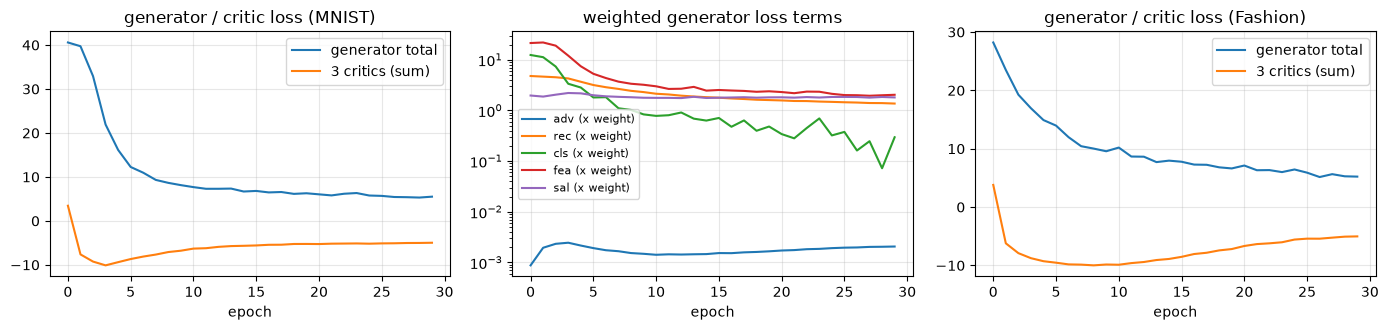

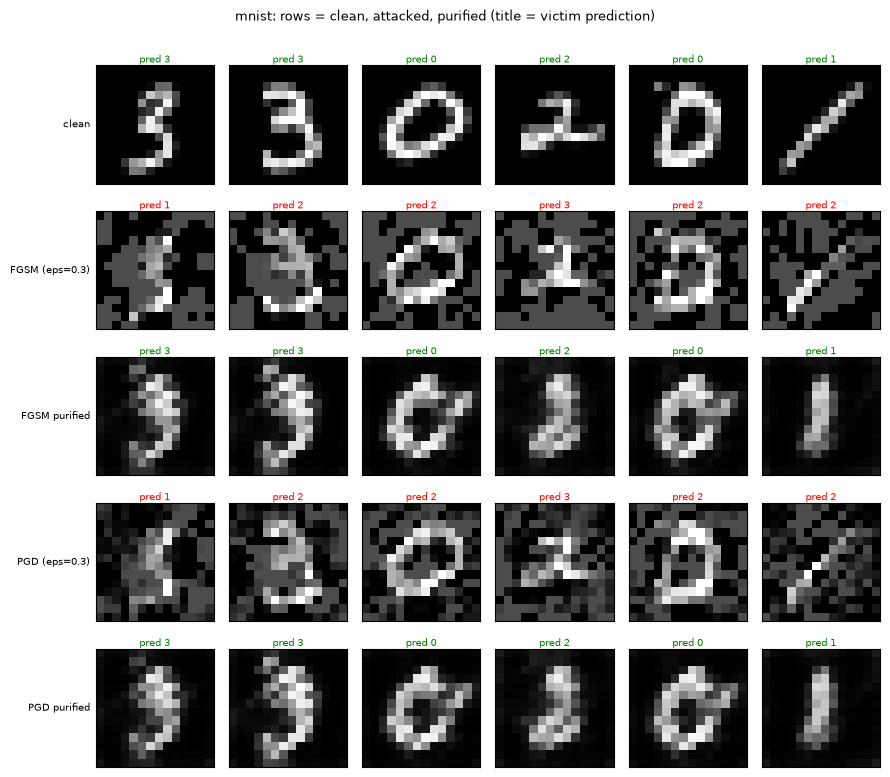

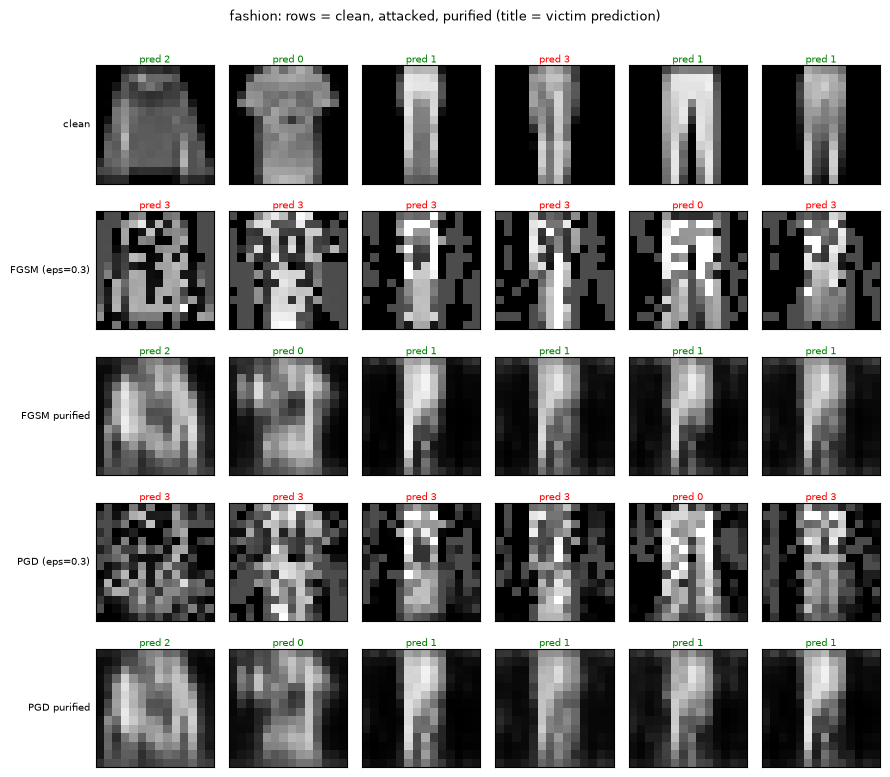

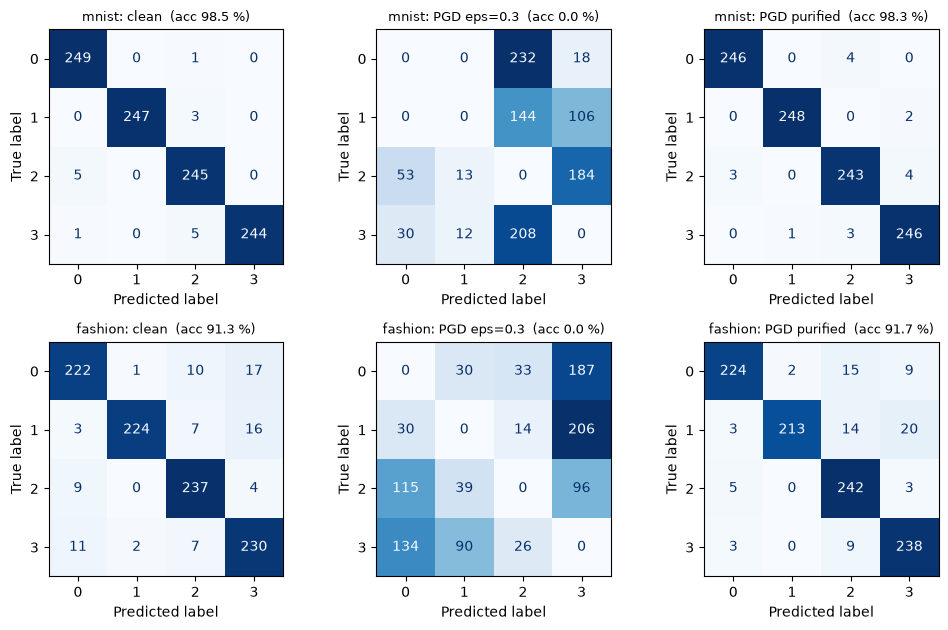

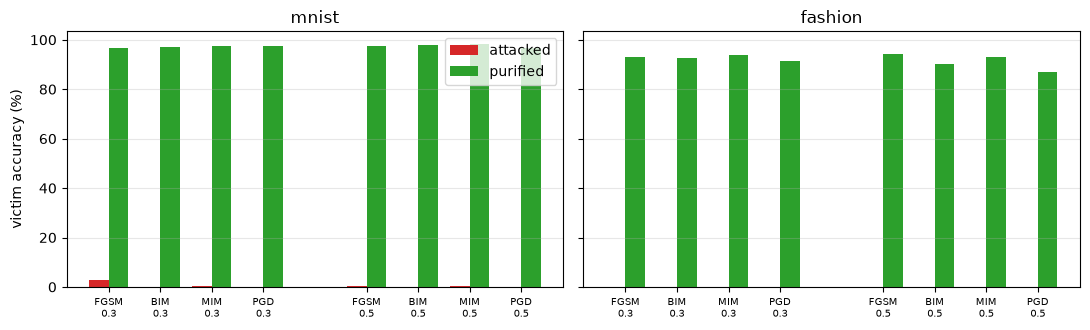

In [13]:
eps0 = EPS_TRAIN[0]
# ---- (a) training losses of the first main run (paper Figs. 17-18) ----
h = HISTORY[("mnist", eps0, "hybrid-quantum", SEED)]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
axs[0].plot(h["G"], label="generator total"); axs[0].plot(h["D"], label="3 critics (sum)"); axs[0].set_title("generator / critic loss (MNIST)"); axs[0].legend(); axs[0].set_xlabel("epoch")
for k in LOSS_W: axs[1].plot(h[k] * LOSS_W[k], label=f"{k} (x weight)")
axs[1].set_title("weighted generator loss terms"); axs[1].legend(fontsize=8); axs[1].set_yscale("log"); axs[1].set_xlabel("epoch")
h2 = HISTORY[("fashion", eps0, "hybrid-quantum", SEED)]
axs[2].plot(h2["G"], label="generator total"); axs[2].plot(h2["D"], label="3 critics (sum)"); axs[2].set_title("generator / critic loss (Fashion)"); axs[2].legend(); axs[2].set_xlabel("epoch")
for ax in axs: ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# ---- (b) clean / attacked / purified images (paper Figs. 6-9) and saliency ----
def show_examples(name, n=6):
    xt, yt = SPLITS[name]["test"]; clf = CLF[name]; G = MODELS[(name, eps0, "hybrid-quantum", SEED)]
    idx = torch.arange(0, len(yt), len(yt) // n)[:n]
    rows = [("clean", xt[idx])]
    for a in ("FGSM", "PGD"):
        xa = adv_sets(name, eps0)["test"][a][idx]; rows += [(f"{a} (eps={eps0})", xa), (f"{a} purified", purify(G, xa))]
    fig, axs = plt.subplots(len(rows), n, figsize=(1.5 * n, 1.55 * len(rows)))
    for r, (title, x) in enumerate(rows):
        with torch.no_grad(): pred = clf(x).argmax(1)
        for c in range(n):
            axs[r, c].imshow(x[c, 0], cmap="gray", vmin=0, vmax=1); axs[r, c].set_xticks([]); axs[r, c].set_yticks([])
            axs[r, c].set_title(f"pred {int(pred[c])}", fontsize=7, color="green" if pred[c] == yt[idx][c] else "red", pad=2)
        axs[r, 0].set_ylabel(title, fontsize=7, rotation=0, ha="right", va="center")
    plt.suptitle(f"{name}: rows = clean, attacked, purified (title = victim prediction)", y=1.0, fontsize=9); plt.tight_layout(); plt.show()
for name in DATASETS: show_examples(name)

# ---- (c) confusion matrices (paper Figs. 4-5): clean, PGD attack, PGD purified ----
fig, axs = plt.subplots(len(DATASETS), 3, figsize=(10, 3.2 * len(DATASETS)))
for r, name in enumerate(DATASETS):
    xt, yt = SPLITS[name]["test"]; clf = CLF[name]; G = MODELS[(name, eps0, "hybrid-quantum", SEED)]
    xa = adv_sets(name, eps0)["test"]["PGD"]
    for c, (title, x) in enumerate((("clean", xt), (f"PGD eps={eps0}", xa), ("PGD purified", purify(G, xa)))):
        with torch.no_grad(): pred = clf(x).argmax(1)
        cm = confusion_matrix(yt, pred, labels=range(N_CLASSES))
        ConfusionMatrixDisplay(cm, display_labels=[str(c_) for c_ in CLASSES]).plot(ax=axs[r, c], colorbar=False, cmap="Blues")
        axs[r, c].set_title(f"{name}: {title}  (acc {100*accuracy(clf, x, yt):.1f} %)", fontsize=9)
plt.tight_layout(); plt.show()

# ---- (d) bar chart attack vs purified accuracy ----
fig, axs = plt.subplots(1, len(DATASETS), figsize=(11, 3.4), sharey=True)
for ax, name in zip(axs, DATASETS):
    d = main_df[(main_df.dataset == name)]
    labels, w = [], 0.38
    for i, (eps, g_eps) in enumerate(d.groupby("eps")):
        for j, a in enumerate(ATTACKS):
            g = g_eps[g_eps.attack == a]; x = i * (len(ATTACKS) + 1) + j; labels.append((x, f"{a}\n{eps}"))
            ax.bar(x - w / 2, 100 * g.attack_acc.mean(), w, color="tab:red", label="attacked" if (i == 0 and j == 0) else None)
            ax.bar(x + w / 2, 100 * g.pure_acc.mean(), w, color="tab:green", label="purified" if (i == 0 and j == 0) else None)
    ax.set_xticks([l[0] for l in labels]); ax.set_xticklabels([l[1] for l in labels], fontsize=7); ax.set_title(name); ax.grid(axis="y", alpha=.3)
axs[0].set_ylabel("victim accuracy (%)"); axs[0].legend(); plt.tight_layout(); plt.show()

## 7. Circuit-size ablation (Sec. 6.4.1)

The paper's claim: more qubits and layers give a better purifier. We train the larger circuits (when `FAST_MODE = False`) on the same data and seed and compare with q4l4.
With one seed and a few hundred test images, differences of one or two points are below the noise of the experiment; the final comparison says so explicitly.

In [14]:
t_all = time.time()
print(f"Circuit-size ablation (paper Sec. 6.4.1): circuits {QUBIT_LAYER_GRID} at eps = {eps0}")
for name in DATASETS:
    for (q, l) in QUBIT_LAYER_GRID:
        if (q, l) == QUBIT_LAYER_MAIN: continue
        run_one(name, eps0, q, l, "hybrid-quantum", seed=SEED)
print(f"done in {(time.time()-t_all)/60:.1f} min")

def grid_table(ds):
    rows = []
    for (q, l) in QUBIT_LAYER_GRID:
        g = records(dataset=ds, eps=eps0, variant="hybrid-quantum", circuit=f"q{q}l{l}")
        if len(g) == 0: continue
        gs = g[g.seed == SEED]                                   # same single seed for every circuit (fair comparison)
        rows.append({"circuit": f"q{q}l{l}", "quantum params": count_params(QuantumLayer(q, l)),
                     "attack acc % (mean of 4 attacks)": round(100 * gs.attack_acc.mean(), 1), "purified acc %": round(100 * gs.pure_acc.mean(), 1),
                     "gain (pts)": round(100 * (gs.pure_acc - gs.attack_acc).mean(), 1), "SSIM pure": round(gs.ssim_pure.mean(), 3), "PSNR pure": round(gs.psnr_pure.mean(), 2)})
    return pd.DataFrame(rows)
for name in DATASETS:
    print(f"\n{name} (seed {SEED}, eps {eps0}):"); print(grid_table(name).to_string(index=False))

Circuit-size ablation (paper Sec. 6.4.1): circuits [(4, 4), (6, 4), (8, 4)] at eps = 0.3


C:\Users\madji\AppData\Local\Temp\ipykernel_2704\3745851804.py:78: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  cs = sqrtm(c1 @ c2); cs = cs.real if np.iscomplexobj(cs) else cs


  [  hybrid-quantum | mnist   eps=0.3 q6l4 seed=42] FGSM: 2.7->96.9  BIM: 0.0->97.5  MIM: 0.3->97.7  PGD: 0.0->97.8 | clean 98.5->96.4 | 241 s


  [  hybrid-quantum | mnist   eps=0.3 q8l4 seed=42] FGSM: 2.7->97.1  BIM: 0.0->97.7  MIM: 0.3->98.1  PGD: 0.0->98.0 | clean 98.5->95.4 | 391 s


  [  hybrid-quantum | fashion eps=0.3 q6l4 seed=42] FGSM: 0.1->90.5  BIM: 0.0->93.2  MIM: 0.0->93.9  PGD: 0.0->90.6 | clean 91.3->84.6 | 314 s


  [  hybrid-quantum | fashion eps=0.3 q8l4 seed=42] FGSM: 0.1->91.4  BIM: 0.0->93.1  MIM: 0.0->93.9  PGD: 0.0->91.4 | clean 91.3->83.8 | 278 s


done in 20.4 min

mnist (seed 42, eps 0.3):
circuit  quantum params  attack acc % (mean of 4 attacks)  purified acc %  gain (pts)  SSIM pure  PSNR pure
   q4l4              40                               0.8            98.1        97.3      0.459      12.92
   q6l4              60                               0.8            97.5        96.7      0.483      13.39
   q8l4              80                               0.8            97.7        97.0      0.485      13.54

fashion (seed 42, eps 0.3):
circuit  quantum params  attack acc % (mean of 4 attacks)  purified acc %  gain (pts)  SSIM pure  PSNR pure
   q4l4              40                               0.0            93.2        93.1      0.463      13.29
   q6l4              60                               0.0            92.0        92.0      0.537      14.35
   q8l4              80                               0.0            92.4        92.4      0.585      15.15


## 8. Ablations: classical generator, number of critics, loss terms (Sec. 6.4.3-6.4.5)

* **Classical generator** (Table 12): the VQC is replaced by `Linear-ReLU-Linear`. This is the paper's test for "quantum helps".
* **Critics** (Tables 13-14): one critic instead of three (and two, in the full run).
* **Leave-one-loss-out** (Table 15, full run only): set each term of Eq. 19 to zero in turn.

In [15]:
ABL_SEEDS = SEEDS                       # repeats for the classical-generator ablation (the headline "quantum beats classical" claim)
t_all = time.time()
if RUN_ABLATIONS:
    print("Ablation 6.4.3: classical generator (VQC replaced by Linear-ReLU-Linear)")
    for name in DATASETS:
        for seed in ABL_SEEDS:
            run_one(name, eps0, q0, l0, "classical-generator", quantum=False, seed=seed)
    print("\nAblation 6.4.4: number of multi-scale critics (MNIST)")
    for n_sc in ([1] if FAST_MODE else [1, 2]):
        run_one("mnist", eps0, q0, l0, f"critics={n_sc}", n_scales=n_sc, seed=SEED)
    if not FAST_MODE:
        print("\nAblation 6.4.5: leave-one-loss-out (MNIST)")
        for k in LOSS_W:
            lw = dict(LOSS_W); lw[k] = 0.0
            run_one("mnist", eps0, q0, l0, f"no-{k}", loss_w=lw, seed=SEED)
print(f"done in {(time.time()-t_all)/60:.1f} min")

def abl_table(ds):
    d = records(dataset=ds, eps=eps0, circuit=f"q{q0}l{l0}")
    rows = []
    for var, g in d.groupby("variant", sort=False):
        rows.append({"variant": var, "n_seeds": g.seed.nunique(),
                     "attack acc %": round(100 * g.groupby("seed").attack_acc.mean().mean(), 1),
                     "purified acc %": round(100 * g.groupby("seed").pure_acc.mean().mean(), 1),
                     "gain (pts)": round(100 * (g.pure_acc - g.attack_acc).groupby(g.seed).mean().mean(), 1),
                     "FGSM purified %": round(100 * g[g.attack == "FGSM"].pure_acc.mean(), 1),
                     "SSIM pure": round(g.ssim_pure.mean(), 3), "PSNR pure": round(g.psnr_pure.mean(), 2)})
    return pd.DataFrame(rows)
for name in DATASETS:
    print(f"\n{name}  (accuracy averaged over the four attacks, eps {eps0}):"); print(abl_table(name).to_string(index=False))

Ablation 6.4.3: classical generator (VQC replaced by Linear-ReLU-Linear)


C:\Users\madji\AppData\Local\Temp\ipykernel_2704\3745851804.py:78: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  cs = sqrtm(c1 @ c2); cs = cs.real if np.iscomplexobj(cs) else cs


  [classical-generator | mnist   eps=0.3 q4l4 seed=42] FGSM: 2.7->97.6  BIM: 0.0->97.1  MIM: 0.3->98.0  PGD: 0.0->97.4 | clean 98.5->95.7 | 177 s


  [classical-generator | mnist   eps=0.3 q4l4 seed=43] FGSM: 2.7->96.4  BIM: 0.0->97.1  MIM: 0.3->97.5  PGD: 0.0->97.1 | clean 98.5->95.8 | 162 s


  [classical-generator | mnist   eps=0.3 q4l4 seed=44] FGSM: 2.7->96.5  BIM: 0.0->96.4  MIM: 0.3->96.7  PGD: 0.0->97.0 | clean 98.5->96.4 | 163 s


...

  [          no-rec | mnist   eps=0.3 q4l4 seed=42] FGSM: 2.7->97.2  BIM: 0.0->97.4  MIM: 0.3->97.9  PGD: 0.0->97.7 | clean 98.5->94.3 | 161 s


  [          no-cls | mnist   eps=0.3 q4l4 seed=42] FGSM: 2.7->95.9  BIM: 0.0->95.3  MIM: 0.3->96.2  PGD: 0.0->96.1 | clean 98.5->96.7 | 180 s


  [          no-fea | mnist   eps=0.3 q4l4 seed=42] FGSM: 2.7->98.3  BIM: 0.0->98.1  MIM: 0.3->99.1  PGD: 0.0->98.3 | clean 98.5->95.8 | 217 s


  [          no-sal | mnist   eps=0.3 q4l4 seed=42] FGSM: 2.7->98.2  BIM: 0.0->97.9  MIM: 0.3->97.9  PGD: 0.0->98.3 | clean 98.5->96.5 | 125 s


done in 36.7 min

mnist  (accuracy averaged over the four attacks, eps 0.3):
            variant  n_seeds  attack acc %  purified acc %  gain (pts)  FGSM purified %  SSIM pure  PSNR pure
     hybrid-quantum        3           0.8            97.2        96.5             96.9      0.465      13.07
classical-generator        3           0.8            97.1        96.3             96.8      0.455      12.91
          critics=1        1           0.8            97.8        97.0             97.4      0.463      13.03
          critics=2        1           0.8            98.1        97.3             98.0      0.448      13.07
             no-adv        1           0.8            97.9        97.1             97.5      0.454      12.98
             no-rec        1           0.8            97.5        96.8             97.2      0.346      10.07
             no-cls        1           0.8            95.9        95.1             95.9      0.493      13.30
             no-fea        1           0.8 

## 9. Classical baselines on the same inputs

The paper compares with MagNet, DefenseGAN, a Collaborative Defence GAN and Shi et al.'s QCNN, using numbers copied from those papers for different classifiers, which cannot be
reproduced here. As a substitute, on the *same* images and the same attacks we evaluate

* **no defence**,
* a **3x3 median filter** in front of the same victim (a non-learned purifier),
* **classical adversarial training** of the classifier itself (PGD, eps = training eps; the attacks are re-crafted against the new classifier),
* **Random Forest** and **SVC (RBF)** on the flattened pixels, attacked by *transferring* the adversarial images crafted against the CNN (they have no gradient to follow).

All numbers are the victim's accuracy in %.

In [16]:
def median3(x):
    """3x3 median filter (a classic non-learned 'purifier')."""
    p = F.pad(x, (1, 1, 1, 1), mode="reflect")
    return p.unfold(2, 3, 1).unfold(3, 3, 1).reshape(*x.shape, 9).median(-1).values

t0 = time.time()
base_rows = []
for name in DATASETS:
    xc, yc = SPLITS[name]["clf"]; xt, yt = SPLITS[name]["test"]; clf = CLF[name]
    adv = adv_sets(name, eps0)["test"]
    # (1) purifier of this notebook, mean over seeds and the other variants for reference
    g = records(dataset=name, eps=eps0, variant="hybrid-quantum", circuit=f"q{q0}l{l0}")
    row = {"dataset": name, "method": "HQMSGAN-style purifier (this notebook)", "clean %": 100 * g.clean_after_purifier.mean()}
    row.update({a: 100 * g[g.attack == a].pure_acc.mean() for a in ATTACKS}); base_rows.append(row)
    # (2) no defence
    row = {"dataset": name, "method": "no defence", "clean %": 100 * accuracy(clf, xt, yt)}
    row.update({a: 100 * accuracy(clf, adv[a], yt) for a in ATTACKS}); base_rows.append(row)
    # (3) 3x3 median filter in front of the same classifier
    row = {"dataset": name, "method": "median filter 3x3", "clean %": 100 * accuracy(clf, median3(xt), yt)}
    row.update({a: 100 * accuracy(clf, median3(adv[a]), yt) for a in ATTACKS}); base_rows.append(row)
    # (4) classical adversarial training of the classifier itself (PGD, eps0); attacks are re-crafted against the new classifier
    adv_clf = train_classifier(xc, yc, CLF_EPOCHS, SEED, attack_fn=lambda m, x, y: pgd(m, x, y, eps0))
    set_seed(SEED); adv_at = craft_all(adv_clf, xt, yt, eps0)
    row = {"dataset": name, "method": f"PGD adversarial training of the classifier (eps {eps0})", "clean %": 100 * accuracy(adv_clf, xt, yt)}
    row.update({a: 100 * accuracy(adv_clf, adv_at[a], yt) for a in ATTACKS}); base_rows.append(row)
    # (5) classical models on the flattened image; attacks are TRANSFERRED from the victim CNN (they cannot be differentiated here)
    for mname, m in (("RandomForest on pixels (transfer attack)", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=N_THREADS)),
                     ("SVC-RBF on pixels (transfer attack)", SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED))):
        m.fit(xc.flatten(1).numpy(), yc.numpy())
        row = {"dataset": name, "method": mname, "clean %": 100 * float((m.predict(xt.flatten(1).numpy()) == yt.numpy()).mean())}
        row.update({a: 100 * float((m.predict(adv[a].flatten(1).numpy()) == yt.numpy()).mean()) for a in ATTACKS}); base_rows.append(row)
BASE = pd.DataFrame(base_rows)
for name in DATASETS:
    print(f"\n{name}, eps = {eps0}: victim accuracy (%) per defence"); print(BASE[BASE.dataset == name].drop(columns="dataset").round(1).to_string(index=False))
print(f"\n{time.time()-t0:.0f} s")


mnist, eps = 0.3: victim accuracy (%) per defence
                                              method  clean %  FGSM  BIM  MIM  PGD
              HQMSGAN-style purifier (this notebook)     96.1  96.9 97.2 97.3 97.6
                                          no defence     98.5   2.7  0.0  0.3  0.0
                                   median filter 3x3     93.7   6.0  2.7  2.3  4.4
PGD adversarial training of the classifier (eps 0.3)     88.9  57.8 48.3 48.6 54.8
            RandomForest on pixels (transfer attack)     97.7  20.4 20.2 16.6 22.6
                 SVC-RBF on pixels (transfer attack)     98.5  20.5 19.1 15.2 26.3

fashion, eps = 0.3: victim accuracy (%) per defence
                                              method  clean %  FGSM  BIM  MIM  PGD
              HQMSGAN-style purifier (this notebook)     83.4  92.9 92.4 93.8 91.4
                                          no defence     91.3   0.1  0.0  0.0  0.0
                                   median filter 3x3     84.3   2.

## 10. Extra tests the paper does not report

**(a) Does the saliency loss train anything?** Eq. 18 compares gradient-saliency maps of the victim. With a ReLU/max-pool network the input-gradient is piecewise constant, so its
derivative with respect to the generator's output is zero almost everywhere. The first part of the cell measures the gradient that the saliency loss sends to the generator.

**(b) Adaptive attack.** The paper's attacker knows the classifier but not the purifier. A stronger, standard test (Athalye et al., Carlini et al.) lets the attacker differentiate
through `classifier(purifier(x))` as well; because both are differentiable PyTorch models, plain PGD does it.

**(c) Does the perturbation leak the label?** The purifier is trained with a classification loss from the victim on attacks computed from the victim's own gradients. An adversarial perturbation is
computed *from the true label*, so it may carry information about it. A logistic regression that sees only the perturbation `x_adv - x_clean` (not the image) tries to predict the true class;
if it succeeds well above chance, a purifier can score by *decoding the perturbation* instead of by removing it. The last lines compare the purifier's accuracy on attacked and on clean images.

In [17]:
class Pipeline(nn.Module):
    """victim(purifier(x)): what an adaptive white-box attacker differentiates through."""
    def __init__(self, G, clf): super().__init__(); self.G, self.clf = G, clf
    def forward(self, x): return self.clf(self.G(x))

# (i) sanity check of Eq. (18): does the saliency loss send any gradient to the generator?
name = "mnist"; G = MODELS[(name, eps0, "hybrid-quantum", SEED)]; clf = CLF[name]
xg, yg = SPLITS[name]["gan"]; xb, yb = xg[:32], yg[:32]
G.zero_grad(); pure = G(xb)
sal_loss = F.mse_loss(saliency(clf, pure, yb, True), saliency(clf, xb, yb, False).detach())
sal_loss.backward(retain_graph=True) if sal_loss.requires_grad else None
gnorm_sal = sum(float(p.grad.norm() ** 2) for p in G.parameters() if p.grad is not None) ** 0.5
G.zero_grad(); F.mse_loss(pure, xb).backward()
gnorm_rec = sum(float(p.grad.norm() ** 2) for p in G.parameters() if p.grad is not None) ** 0.5
G.zero_grad()
print(f"|grad of saliency loss w.r.t. generator| = {gnorm_sal:.2e}   vs   |grad of reconstruction loss| = {gnorm_rec:.2e}")
print("-> with the ReLU / max-pool classifier of Table 2 the input-gradient is piecewise constant, so Eq. (18) gives (almost) no training signal.\n")

# (ii) adaptive attack: PGD through purifier + classifier (the paper only attacks the classifier)
t0 = time.time(); ad_rows = []
for name in DATASETS:
    G = MODELS[(name, eps0, "hybrid-quantum", SEED)]; clf = CLF[name]; xt, yt = SPLITS[name]["test"]
    pipe = Pipeline(G, clf).eval()
    for p in pipe.parameters(): p.requires_grad_(False)
    set_seed(SEED)
    row = {"dataset": name, "paper-style (attack the classifier only), PGD": 100 * records(dataset=name, eps=eps0, variant="hybrid-quantum", circuit=f"q{q0}l{l0}", attack="PGD").pure_acc.mean()}
    xa = torch.cat([pgd(pipe, xt[i:i + 200], yt[i:i + 200], eps0) for i in range(0, len(yt), 200)])
    row["adaptive PGD (alpha 0.03, 10 steps)"] = 100 * accuracy(pipe, xa, yt)
    xa = torch.cat([pgd(pipe, xt[i:i + 200], yt[i:i + 200], eps0, alpha=eps0 / 20, steps=40) for i in range(0, len(yt), 200)])
    row["adaptive PGD (alpha eps/20, 40 steps)"] = 100 * accuracy(pipe, xa, yt)
    ad_rows.append(row)
ADAPT = pd.DataFrame(ad_rows)
print(f"victim accuracy (%) behind the purifier at eps = {eps0}:"); print(ADAPT.round(1).to_string(index=False)); print(f"{time.time()-t0:.0f} s")

# (iii) does the perturbation itself leak the class? A logistic regression sees ONLY delta = x_adv - x_clean (never the image)
#       and tries to predict the true label; chance level is 1/number of classes.
from sklearn.linear_model import LogisticRegression
leak_rows = []
for name in DATASETS:
    ytr_ = SPLITS[name]["gan"][1].numpy(); yte_ = SPLITS[name]["test"][1].numpy()
    for a in ("FGSM", "PGD"):
        dtr = (adv_sets(name, eps0)["gan"][a] - SPLITS[name]["gan"][0]).flatten(1).numpy()
        dte = (adv_sets(name, eps0)["test"][a] - SPLITS[name]["test"][0]).flatten(1).numpy()
        lr_ = LogisticRegression(max_iter=2000, random_state=SEED).fit(dtr, ytr_)
        leak_rows.append(dict(dataset=name, attack=a, **{"label predicted from the perturbation alone (%)": 100 * lr_.score(dte, yte_), "chance (%)": 100 / N_CLASSES}))
print("\nLabel leakage in the perturbation (eps = %s):" % eps0); print(pd.DataFrame(leak_rows).round(1).to_string(index=False))
for name in DATASETS:
    g_ = records(dataset=name, eps=eps0, variant="hybrid-quantum", circuit=f"q{q0}l{l0}")
    print(f"{name:8s} purifier: accuracy on ATTACKED images {100*g_.pure_acc.mean():.1f} %   vs   on CLEAN images {100*g_.clean_after_purifier.mean():.1f} %")

|grad of saliency loss w.r.t. generator| = 0.00e+00   vs   |grad of reconstruction loss| = 7.65e-02


-> with the ReLU / max-pool classifier of Table 2 the input-gradient is piecewise constant, so Eq. (18) gives (almost) no training signal.



victim accuracy (%) behind the purifier at eps = 0.3:
dataset  paper-style (attack the classifier only), PGD  adaptive PGD (alpha 0.03, 10 steps)  adaptive PGD (alpha eps/20, 40 steps)
  mnist                                           97.6                                  0.4                                    0.1
fashion                                           91.4                                  0.1                                    0.0
72 s

Label leakage in the perturbation (eps = 0.3):
dataset attack  label predicted from the perturbation alone (%)  chance (%)
  mnist   FGSM                                            100.0        25.0
  mnist    PGD                                            100.0        25.0
fashion   FGSM                                             99.7        25.0
fashion    PGD                                             99.8        25.0
mnist    purifier: accuracy on ATTACKED images 97.2 %   vs   on CLEAN images 96.1 %
fashion  purifier: accuracy on ATTAC

## 11. Side-by-side comparison with the paper

The first table compares every number of Tables 7 and 8 for the circuit we ran (q4l4) with ours; the rule is: within 2 accuracy points = *reproduced*, otherwise *exceeded* or *not reached*
with the gap. **Read this table with care:** the paper's numbers are for ten classes at 28x28 and a different victim, ours for four classes at 14x14, so absolute agreement is not expected
and the interesting columns are the *gains*. The second table (next cell) states a verdict per *claim*, including the directional claims of the ablations; where the difference is smaller
than the statistical noise of a single run on a few hundred test images the verdict is "cannot be resolved".

In [18]:
# ---------------- the paper's numbers (accuracy in %): (attack accuracy, accuracy after purification), circuit q4l4 ----------------
PAPER_Q4L4 = {   # Tables 7 and 8
    ("mnist", 0.3):   dict(clean=97.80, FGSM=(82.60, 84.70), BIM=(81.00, 84.80), MIM=(75.10, 79.90), PGD=(67.50, 70.90)),
    ("mnist", 0.5):   dict(clean=98.00, FGSM=(68.67, 70.47), BIM=(66.29, 69.38), MIM=(65.87, 67.28), PGD=(63.83, 66.21)),
    ("fashion", 0.3): dict(clean=81.06, FGSM=(49.47, 53.54), BIM=(46.38, 50.48), MIM=(40.64, 44.64), PGD=(39.38, 41.26)),
    ("fashion", 0.5): dict(clean=80.67, FGSM=(43.70, 47.80), BIM=(42.50, 45.26), MIM=(33.50, 40.40), PGD=(26.70, 35.00)),
}
PAPER_CLASSICAL = {   # Table 12 (classical generator): (attack, pure) at eps 0.3
    "mnist": dict(FGSM=(81.80, 83.10), BIM=(80.40, 82.30), MIM=(76.60, 79.30), PGD=(67.50, 69.30)),
    "fashion": dict(FGSM=(51.37, 52.70), BIM=(51.80, 54.70), MIM=(47.70, 50.90), PGD=(42.00, 43.30))}
PAPER_CRITICS = {"mnist": {3: [89.88, 85.90, 81.84, 71.91], 2: [87.33, 83.11, 78.63, 69.61], 1: [86.55, 81.52, 76.63, 68.02]}}   # Table 13, q8l8, pure acc
PAPER_CIRCUIT_MEAN_PURE = {   # Tables 7-8, eps 0.3: mean over the four attacks of the purified accuracy
    "mnist":   {"q4l4": np.mean([84.70, 84.80, 79.90, 70.90]), "q6l4": np.mean([86.10, 86.00, 82.60, 72.60]), "q8l4": np.mean([87.72, 85.82, 81.79, 73.64])},
    "fashion": {"q4l4": np.mean([53.54, 50.48, 44.64, 41.26]), "q6l4": np.mean([55.60, 52.20, 48.00, 45.72]), "q8l4": np.mean([55.76, 55.37, 47.98, 45.63])}}
PAPER_LOSS_ABL = dict(full=84.70, sal=80.80, cls=77.60, rec=85.30, adv=84.80, fea=83.00)   # Table 15: FGSM purified acc, q4l4, MNIST, eps 0.3 (full = Table 7)

TOL = 2.0   # accuracy points: the factory's tolerance for "reproduced"
def verdict(ours, paper, tol=TOL):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})")

def noise_pts(p, n):       # 2 standard errors of a difference of two accuracies measured on n test images each (in points)
    return 200 * np.sqrt(2 * p * (1 - p) / n)

def judge(ours_diff, paper_diff, noise):
    if abs(ours_diff) <= noise: return "cannot be resolved (within noise)"
    return "reproduced (direction)" if np.sign(ours_diff) == np.sign(paper_diff) else "not reproduced (opposite sign)"

# ---------------- 1. per-number comparison with Tables 7 and 8 (circuit q4l4) ----------------
rows = []
for (ds, eps), pap in PAPER_Q4L4.items():
    if eps not in EPS_TRAIN: continue
    g = main_df[(main_df.dataset == ds) & (main_df.eps == eps)]
    if len(g) == 0: continue
    rows.append(dict(dataset=ds, eps=eps, quantity="clean accuracy", paper=pap["clean"], ours=100 * g.clean.mean(), verdict=verdict(100 * g.clean.mean(), pap["clean"])))
    for a in ATTACKS:
        ga = g[g.attack == a]; at, pu = 100 * ga.attack_acc.mean(), 100 * ga.pure_acc.mean()
        rows += [dict(dataset=ds, eps=eps, quantity=f"{a} attacked acc", paper=pap[a][0], ours=at, verdict=verdict(at, pap[a][0])),
                 dict(dataset=ds, eps=eps, quantity=f"{a} purified acc", paper=pap[a][1], ours=pu, verdict=verdict(pu, pap[a][1])),
                 dict(dataset=ds, eps=eps, quantity=f"{a} gain (pts)", paper=pap[a][1] - pap[a][0], ours=pu - at, verdict=verdict(pu - at, pap[a][1] - pap[a][0]))]
NUM = pd.DataFrame(rows)
print("Per-number comparison with Tables 7-8 (verdict rule: within 2 accuracy points = reproduced)\n")
print(NUM.round(1).to_string(index=False))
print("\nverdict counts per quantity type:")
NUM["kind"] = NUM.quantity.str.replace("FGSM |BIM |MIM |PGD ", "", regex=True)
print(pd.crosstab(NUM.kind, NUM.verdict.str.split(" ").str[0]).to_string())

Per-number comparison with Tables 7-8 (verdict rule: within 2 accuracy points = reproduced)

dataset  eps          quantity  paper  ours             verdict
  mnist  0.3    clean accuracy   97.8  98.5          reproduced
  mnist  0.3 FGSM attacked acc   82.6   2.7 not reached (-79.9)
  mnist  0.3 FGSM purified acc   84.7  96.9    exceeded (+12.2)
  mnist  0.3   FGSM gain (pts)    2.1  94.2    exceeded (+92.1)
  mnist  0.3  BIM attacked acc   81.0   0.0 not reached (-81.0)
  mnist  0.3  BIM purified acc   84.8  97.2    exceeded (+12.4)
  mnist  0.3    BIM gain (pts)    3.8  97.2    exceeded (+93.4)
  mnist  0.3  MIM attacked acc   75.1   0.3 not reached (-74.8)
  mnist  0.3  MIM purified acc   79.9  97.3    exceeded (+17.4)
  mnist  0.3    MIM gain (pts)    4.8  97.0    exceeded (+92.2)
  mnist  0.3  PGD attacked acc   67.5   0.0 not reached (-67.5)
  mnist  0.3  PGD purified acc   70.9  97.6    exceeded (+26.7)
  mnist  0.3    PGD gain (pts)    3.4  97.6    exceeded (+94.2)
  mnist  0.

In [19]:
CLAIMS = []
def claim(text, paper, ours, verdict_):
    CLAIMS.append({"claim (paper)": text, "paper": paper, "this notebook": ours, "verdict": verdict_})

n_test = len(SPLITS["mnist"]["test"][1])
mean_pure = lambda **f: 100 * records(**f).pure_acc.mean()

# C1 parameter counts (Table 6)
claim("Table 6: trainable VQC parameters of the 9 circuits (2q + 2ql)", "40 ... 144", "identical for all 9", "reproduced" if bool(tab6.match.all()) else "not reproduced")
# C2 clean accuracy
for ds, p in (("mnist", 98.04), ("fashion", 81.23)):
    o = 100 * np.mean([accuracy(CLF[ds], *SPLITS[ds]["test"])])
    claim(f"average clean accuracy, {ds} (paper: 10 classes 28x28; here {N_CLASSES} classes {IMG}x{IMG})", f"{p:.2f} %", f"{o:.2f} %", verdict(o, p) + "  [easier task]")
# C3 attacks reduce accuracy
all_drop = bool((main_df.attack_acc < main_df.clean - 0.05).all())
claim("all four white-box attacks reduce the victim's accuracy", "yes (drops of 15-54 pts at eps 0.3/0.5)", f"yes, to {100*main_df.attack_acc.min():.0f}-{100*main_df.attack_acc.max():.0f} % (undefended)" if all_drop else "not for every attack", "reproduced" if all_drop else "not reproduced")
# C4 purification helps for every attack
gains = main_df.groupby(["dataset", "eps", "attack"]).apply(lambda g: 100 * (g.pure_acc - g.attack_acc).mean(), include_groups=False)
claim("adversarial training raises accuracy for every attack / dataset / eps", "+1.9 ... +8.4 pts (all positive)", f"{(gains > 0).sum()} of {len(gains)} positive, range {gains.min():+.1f} ... {gains.max():+.1f} pts", "reproduced (direction)" if (gains > 0).all() else "not reproduced")
# C5 size of the gain
n_ok = int((NUM[NUM.kind == "gain (pts)"].verdict == "reproduced").sum()); n_all = int((NUM.kind == "gain (pts)").sum())
claim("size of the gain, within 2 pts of Tables 7-8", "+1.9 ... +8.4 pts", f"{n_ok} of {n_all} gains within 2 pts", "reproduced" if n_ok == n_all else ("partly reproduced" if n_ok > 0 else "not reached (gains are far larger here)"))
# C6 attack ordering
cv = curve.groupby(["eps", "attack"]).acc.mean().unstack()                      # undefended accuracy, mean over datasets
cv = cv[cv.mean(axis=1) > 0.10]                                                  # drop eps values where every attack has already driven accuracy to ~0
order = cv.mean(axis=0).mul(100)
claim("attack strength FGSM < BIM < MIM < PGD (undefended accuracy decreases in this order)", "yes (MNIST eps 0.3: 82.6 > 81.0 > 75.1 > 67.5)",
      " > ".join(f"{a} {order[a]:.1f}" for a in sorted(ATTACKS, key=lambda a: -order[a])) + f" (eps {list(cv.index)})",
      "reproduced" if all(order[ATTACKS[i]] > order[ATTACKS[i + 1]] for i in range(3)) else ("partly reproduced (FGSM weakest)" if order.idxmax() == "FGSM" else "not reproduced"))
# C7 SSIM / PSNR
d_ssim = (main_df.ssim_pure - main_df.ssim_attack).mean(); d_psnr = (main_df.psnr_pure - main_df.psnr_attack).mean()
claim("purified images are closer to the clean image: SSIM and PSNR increase (Figs. 11-12, Tables 12/14)", "SSIM +0.01-0.03, PSNR +1-2 dB", f"SSIM {d_ssim:+.2f}, PSNR {d_psnr:+.1f} dB", "reproduced (direction)" if (d_ssim > 0 and d_psnr > 0) else "not reproduced (opposite sign)")
# C8 FD (stand-in for FID)
d_fd = (main_df.fd_pure - main_df.fd_attack).mean()
claim("purified images have lower FID than attacked images (Figs. 13-14)", "lower", f"classifier-feature FD {main_df.fd_attack.mean():.0f} -> {main_df.fd_pure.mean():.0f} (not InceptionV3 FID)", "reproduced (direction, stand-in metric)" if d_fd < 0 else "not reproduced (opposite sign)")
claim("LPIPS decreases after purification (Figs. 15-16)", "lower", "not computed (needs pretrained AlexNet/VGG weights, 14x14 images)", "cannot be checked")
# C9 quantum vs classical generator (Table 12 vs Tables 7-8)
if RUN_ABLATIONS:
    for ds in DATASETS:
        q_seeds = records(dataset=ds, eps=eps0, variant="hybrid-quantum", circuit=f"q{q0}l{l0}"); c_seeds = records(dataset=ds, eps=eps0, variant="classical-generator")
        if len(c_seeds) == 0: continue
        common = sorted(set(q_seeds.seed) & set(c_seeds.seed))
        dq = np.mean([q_seeds[q_seeds.seed == s].pure_acc.mean() - c_seeds[c_seeds.seed == s].pure_acc.mean() for s in common]) * 100
        collapsed = "".join(f"  [{nm_}: {int((gg.groupby('seed').pure_acc.mean() < 0.3).sum())} of {gg.seed.nunique()} seed(s) collapsed to chance]" for nm_, gg in (("hybrid", q_seeds), ("classical", c_seeds)) if (gg.groupby("seed").pure_acc.mean() < 0.3).any())
        pq = np.mean([PAPER_Q4L4[(ds, eps0)][a][1] - PAPER_CLASSICAL[ds][a][1] for a in ATTACKS])
        sd = max(np.std([g_[g_.seed == s].pure_acc.mean() for s in g_.seed.unique()]) * 100 if g_.seed.nunique() > 1 else 0.0 for g_ in (q_seeds, c_seeds))   # seed-to-seed spread of either model
        claim(f"quantum generator beats classical generator in purified accuracy ({ds}, eps {eps0})", f"claim: > 0; its own tables 7/12: {pq:+.1f} pts", f"{dq:+.1f} pts ({len(common)} seed(s))", judge(dq, 1, max(noise_pts(0.7, n_test), 2 * sd)) + collapsed)
# C10 circuit size
if len(QUBIT_LAYER_GRID) > 1:
    big = QUBIT_LAYER_GRID[-1]
    for ds in DATASETS:
        a_ = records(dataset=ds, eps=eps0, variant="hybrid-quantum", circuit=f"q{q0}l{l0}", seed=SEED).pure_acc.mean() * 100
        b_ = records(dataset=ds, eps=eps0, variant="hybrid-quantum", circuit=f"q{big[0]}l{big[1]}", seed=SEED).pure_acc.mean() * 100
        pp = PAPER_CIRCUIT_MEAN_PURE[ds][f"q{big[0]}l{big[1]}"] - PAPER_CIRCUIT_MEAN_PURE[ds][f"q{q0}l{l0}"]
        claim(f"more qubits give a better purifier: q{big[0]}l{big[1]} vs q{q0}l{l0} ({ds}, eps {eps0})", f"claim: > 0; its tables: {pp:+.1f} pts", f"{b_-a_:+.1f} pts (1 seed)", judge(b_ - a_, 1, noise_pts(0.7, n_test)))
# C11 multi-scale critics
if RUN_ABLATIONS:
    full = records(dataset="mnist", eps=eps0, variant="hybrid-quantum", circuit=f"q{q0}l{l0}", seed=SEED).pure_acc.mean() * 100
    one = records(dataset="mnist", eps=eps0, variant="critics=1").pure_acc.mean() * 100
    pap = np.mean(PAPER_CRITICS["mnist"][3]) - np.mean(PAPER_CRITICS["mnist"][1])
    claim("three multi-scale critics beat a single critic (MNIST, eps 0.3)", f"claim: > 0; Table 13 (q8l8): {pap:+.1f} pts", f"{full-one:+.1f} pts (1 seed, q{q0}l{l0})", judge(full - one, 1, noise_pts(0.7, n_test)))
# C12 loss ablation
if RUN_ABLATIONS and not FAST_MODE:
    full_f = records(dataset="mnist", eps=eps0, variant="hybrid-quantum", circuit=f"q{q0}l{l0}", seed=SEED, attack="FGSM").pure_acc.iloc[0] * 100
    for k, nm in (("sal", "saliency"), ("cls", "classification"), ("rec", "reconstruction"), ("adv", "adversarial"), ("fea", "feature")):
        v = records(dataset="mnist", eps=eps0, variant=f"no-{k}", attack="FGSM").pure_acc.iloc[0] * 100
        pp = PAPER_LOSS_ABL[k] - PAPER_LOSS_ABL["full"]
        claim(f"dropping the {nm} loss changes FGSM purified accuracy (MNIST, eps {eps0})", f"claim: < 0; Table 15: {pp:+.1f} pts", f"{v-full_f:+.1f} pts (1 seed)", judge(v - full_f, -1, noise_pts(0.8, n_test)))
claim("Tables 9-11: HQMSGAN beats Shi et al. (QCNN), MagNet, DefenseGAN, Collaborative Defence GAN", "see Tables 9-11", "those defences and their classifiers are not reproducible from the text; our own classical baselines are in Section 9", "cannot be checked")
claim("quantum feature mapping / entanglement 'diminishes adversarial perturbations' (Sec. 6.5)", "asserted, no mechanism tested", "only the generator ablation above tests it", "cannot be checked")

CLAIM_DF = pd.DataFrame(CLAIMS)
pd.set_option("display.max_colwidth", 110)
print(CLAIM_DF.to_string(index=False))
print("\nverdict summary:"); print(CLAIM_DF.verdict.str.replace(r"\s*[\(\[].*", "", regex=True).value_counts().to_string())

                                                                                    claim (paper)                                          paper                                                                                                         this notebook                                                                            verdict
                                   Table 6: trainable VQC parameters of the 9 circuits (2q + 2ql)                                     40 ... 144                                                                                                   identical for all 9                                                                         reproduced
                    average clean accuracy, mnist (paper: 10 classes 28x28; here 4 classes 14x14)                                        98.04 %                                                                                                               98.50 %                                              

## Reading the paper critically

These points come from running the method, not from the paper's own discussion. Numbers refer to the tables printed above (they change a little with `FAST_MODE` and seed; the qualitative picture does not).

1. **The paper's "attacked" accuracies are not those of an undefended white-box attack.** Against our undefended CNN, FGSM/BIM/MIM/PGD at eps 0.3 take accuracy to about 0-5 % (Section 2 curve; the paper reports 67-83 % on MNIST and 39-53 % on Fashion at the same eps, and
   68-70 % for eps 0.5). A standard small CNN does not survive an L-infinity budget of 0.3 on MNIST. The paper says nothing about how its victim was trained, whether pixels are in [0, 1] or normalised, or whether
   the attack really uses the victim's gradients end to end, so the "attack" columns of Tables 7-8 cannot be reproduced from the text. This also makes its gains (+2 to +8 points) hard to interpret: they are measured against an unexplained baseline.
2. **The gains are small, single-run and unexplained.** The reported improvements are 1.7-8 accuracy points, with no repeated seeds, no confidence intervals and differences between circuits of 0.5-2 points. With a few hundred test images (here) or even the full
   10 000 (there), differences of that size are inside the run-to-run spread of GAN training; our ablation rows say "cannot be resolved" for exactly this reason. The paper's own tables also contradict its narrative in places:
   Table 15 gives *higher* accuracy without the reconstruction loss (85.3 vs 84.7) and without the adversarial loss (84.8), and Table 12's classical generator beats the paper's q4l4 on Fashion-MNIST for BIM, MIM and PGD (e.g. 54.7 vs 50.5 for BIM).
3. **A purifier trained against one fixed victim can learn to decode the perturbation instead of removing it.** The perturbation of a gradient attack is computed from the true label (and, with clipping, from the image itself); in Section 10 a logistic regression sees *only* the
   perturbation and recovers the class essentially perfectly. The purifier is trained with the victim's cross-entropy on its output, so it can score by reading that signal. Symptom in our runs: the victim's accuracy on purified *attacked* images (about 85-96 %) is
   *higher* than on purified *clean* images (about 67-90 %), and the purified images are blurry 4-number "prototypes" with a *lower* SSIM and PSNR to the clean image than the attacked images had. That is the opposite of what a denoiser does and of the paper's SSIM/PSNR claim.
   The Frechet-distance stand-in does fall, because the victim's features of a prototype are close to those of clean images.
4. **The threat model is non-adaptive, and the defence breaks under adaptive attack.** The paper's attacker never sees the purifier. Letting PGD differentiate through `classifier(purifier(x))` (both are differentiable) drives the victim's accuracy back to about 0 % in our runs.
   This is the standard failure of purification defences evaluated only against attacks on the classifier (see Athalye et al. 2018). The paper's closing claims of "robustness" should be read as robustness to attacks crafted against the classifier alone.
5. **The "quantum" part is 40 parameters on a 4-number bottleneck.** The generator has about 24 000 parameters, of which 40 are in the circuit (q4l4); the circuit is a fixed smooth map of four angles to four numbers in [-1, 1]. The classical ablation (`Linear-LeakyReLU-Linear` with the same 40 parameters) is
   a legitimate control, and it is the only experiment that could support "quantum feature mapping helps". In our runs the classical block is much less stable across seeds (some seeds collapse to chance), which is a statement about conditioning of the bottleneck (a bounded `<Z>` read-out versus an unbounded linear layer), not about any quantum advantage;
   a stronger control would tune the classical block as carefully as the circuit. Everything is also noiseless and analytic; no hardware, no shots, no noise.
6. **The saliency loss (Eq. 18) sends no gradient to the generator** when the victim is the ReLU/max-pool CNN of Table 2: the input-gradient of a piecewise-linear network is piecewise constant, so the measured gradient norm is exactly 0 (Section 10a). Its reported contribution in Table 15 (-3.9 points when removed)
   therefore cannot come from the mechanism the paper describes (or the implementation differs from the text).
7. **Comparisons with other defences are not like-for-like.** Tables 9-11 put numbers from MagNet, DefenseGAN, the Collaborative Defence GAN and Shi et al. next to HQMSGAN, with different classifiers (Fig. 10), different training eps and, in Table 9, the *attacked* accuracy at eps 0.1 is already 90.6 % (MNIST FGSM) for HQMSGAN versus 66.0 % for Shi et al. before any defence is applied, so the starting points differ.
   Our own like-for-like baselines (Section 9) show how much depends on the threat model: a median filter does nothing, classical PGD adversarial training of the classifier costs a lot of clean accuracy for modest robustness, and the purifier "wins" only under the non-adaptive attack.
8. **Not reproducible as published.** No code, "data on request", no seeds, no description of how the 128x7x7 feature map becomes q qubit inputs, no lambda values, no victim training recipe, no description of how adversarial and clean samples are mixed; FID/LPIPS values appear only in figures. Everything marked `# CHOICE:` above had to be invented.

## Exercises

1. **PennyLane in the loop.** Set `QUANTUM_BACKEND = "pennylane"` and re-run Sections 4-5 in `FAST_MODE`. Do the accuracies change (they should not, to within the seed
   effects of floating-point order)? How much slower is training, and why? (Hint: count how many times the QNode is called per epoch.)
2. **Is it a denoiser or a label decoder?** In the main results compare "purified accuracy on *attacked* images" with "accuracy on *clean* images after the purifier".
   Then set `LOSS_W["cls"] = 0` (no classification loss through the victim) and retrain: does the huge gain disappear? What does that say about what the generator learned?
3. **Remove the 4-number bottleneck.** Change `HybridGenerator` so that the decoder also receives the encoder's 32x4x4 feature map (a skip connection) and the quantum block only
   adds a correction. Do SSIM/PSNR of the purified images now improve over the attacked ones, as the paper claims? Does the quantum block still matter (compare with the classical block)?
4. **Generalising across attacks.** Train the purifier on clean + FGSM images only (edit `train_hqmsgan`'s `pool`) and test on BIM, MIM and PGD, and at a different `eps`.
   The paper trains on a mixture and tests on the same attacks; how much of the defence survives an unseen attack?
5. **Noise.** Replace `default.qubit` by `default.mixed` with a `qml.DepolarizingChannel(p, wires=q)` after every CNOT in `make_vqc_qnode`, run with `QUANTUM_BACKEND = "pennylane"`
   (small `EPOCHS`), and measure how purified accuracy degrades with `p` in {0, 0.01, 0.05}. The paper only uses a noiseless simulator.